# Coil flux review

Tests of the coil-flux calculation against true DIII-D flux maps. Sections follow
`docs/COIL_FLUX.md`, "Review notebook". Cells are run manually, top to bottom. Inputs come
from the frame table (`../../data/processed/frame_table`), the Green's tables from
`scripts/build_green_tables.py` (`../../data/processed/green`), and the true maps and stored
axes from the raw DIII-D training files. No MAST equilibrium label is read: the MAST file
opened in section 1 is a public test shot and only its geometry, grid and column names are
used.

Sections 1 to 3 are the single-frame tests (D1, D3a, D3b) that fix the sign rule before the
scale fit. Sections 4 to 7 are filled after `scripts/fit_coil_scales.py` has run.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Polygon

from fusion_eq import coil_scales as cs, dataset, frame_table as ft, grad_shafranov as gs, io, starter_kit
from fusion_eq.coil_flux import GEOMETRY_COLUMNS, GRID_COLUMNS, CoilGeometry, GreenTable, element_outline, near_coil_mask
from fusion_eq.machines import machine_config

DATA_ROOT = Path("../../data/raw/data")
TABLE_DIR = Path("../../data/processed/frame_table")
GREEN_DIR = Path("../../data/processed/green")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 4)

CFG = machine_config("DIII-D")
SCORER = starter_kit.scoring()
ENV = starter_kit.envelope_mask(CFG)
TABLES = {m: GreenTable.load(GREEN_DIR / f"green_{machine_config(m).file_prefix.split('_')[0]}.npz")
          for m in ("DIII-D", "MAST")}
build = json.loads((GREEN_DIR / "build.json").read_text())
index = pd.read_parquet(TABLE_DIR / "shot_index.parquet")

print(f"Green's tables built {build['timestamp']}, commit {str(build['repo_commit'])[:10]}, "
      f"{build['arguments']['n_filaments']} filaments per shorter side")
for m, info in build["machines"].items():
    print(f"  {m}: {info['n_elements']} elements, K1 {info['k1']['status']}, "
          f"K2 {info['k2']['status_other']} ({info['k2']['max_rel_change_other']:.2e} away from coils, "
          f"{info['k2']['max_rel_change_near_coil']:.2e} within one cell)")
for m, t in TABLES.items():
    assert t.n_filaments == build["arguments"]["n_filaments"], f"{m}: table and build.json disagree"
    print(f"  {m} table: {len(t.columns)} columns, grid R {t.grid_r[0]:.2f} to {t.grid_r[-1]:.2f} m, "
          f"Z {t.grid_z[0]:.2f} to {t.grid_z[-1]:.2f} m")


def read(split, columns=None, shots=None):
    return ft.read_frame_table(split, columns, shots, root=TABLE_DIR)

Green's tables built 2026-10-06T21:28:41+00:00, commit ecc981867b, 16 filaments per shorter side
  DIII-D: 19 elements, K1 pass, K2 pass (7.63e-05 away from coils, 2.69e-04 within one cell)
  MAST: 812 elements, K1 pass, K2 pass (1.67e-06 away from coils, 1.54e-05 within one cell)
  DIII-D table: 19 columns, grid R 0.84 to 2.54 m, Z -1.60 to 1.60 m
  MAST table: 11 columns, grid R 0.06 to 2.00 m, Z -2.00 to 2.00 m


## 1. Coils on the grid, both machines (D1)

Every coil element drawn over the grid outline and the scorer's plasma envelope, coloured by
current column. Geometry is read from one shot per machine: the first DIII-D training file and
the first MAST public test file (inputs only). The geometry hash must match the one the Green's
table was built from, and every `coil_input_column` must be a current column with a turn
convention on the machine and a column of the shot file (K1). DIII-D's six sheared coils
(F5A/B, F6A/B, F7A/B) should sit as parallelograms where the README places them; a wrong skew
convention shows as a misplaced or distorted pair.

In [2]:
GEOMETRY, GEOMETRY_SHOT = {}, {}
for machine, split in (("DIII-D", "diii_d_train"), ("MAST", "mast_public_test")):
    cfg = machine_config(machine)
    path = dataset.list_shots(DATA_ROOT, split)[0]
    shot = io.load_shot(path, [*GEOMETRY_COLUMNS, *GRID_COLUMNS], apply=False)
    geometry = CoilGeometry.from_shot(shot)
    problems = geometry.check_against_machine(cfg, shot.file_columns)
    table = TABLES[machine]
    assert geometry.hash() == table.geometry_hash, f"{machine}: geometry differs from the Green's table"
    assert np.allclose(shot["efit_grid_R"], table.grid_r) and np.allclose(shot["efit_grid_Z"], table.grid_z)
    GEOMETRY[machine], GEOMETRY_SHOT[machine] = geometry, path.name
    counts = geometry.elements_per_column()
    print(f"{machine} ({path.name}): {geometry.n_elements} elements in {len(counts)} columns; "
          f"K1 {'pass' if not problems else 'fail: ' + '; '.join(problems)}")
    print("  " + ", ".join(f"{c.replace('magnetics_', '')}={n}" for c, n in counts.items()))
    skewed = [(geometry.names[i], geometry.angle1[i], geometry.angle2[i])
              for i in range(geometry.n_elements) if geometry.angle1[i] != 0 or geometry.angle2[i] != 0]
    print(f"  skewed elements: {skewed if skewed else 'none'}")
NEAR_COIL = near_coil_mask(GEOMETRY["DIII-D"], TABLES["DIII-D"].grid_r, TABLES["DIII-D"].grid_z)
print(f"DIII-D nodes within one cell of a coil outline: {int(NEAR_COIL.sum())} of {NEAR_COIL.size}")

DIII-D (d3d_shot_00000a10ac.parquet): 19 elements in 19 columns; K1 pass
  F1A=1, F2A=1, F3A=1, F4A=1, F5A=1, F6A=1, F7A=1, F8A=1, F9A=1, F1B=1, F2B=1, F3B=1, F4B=1, F5B=1, F6B=1, F7B=1, F8B=1, F9B=1, ECOILA=1
  skewed elements: [(np.str_('F5A'), np.float64(45.0), np.float64(0.0)), (np.str_('F6A'), np.float64(0.0), np.float64(92.4)), (np.str_('F7A'), np.float64(0.0), np.float64(108.06)), (np.str_('F5B'), np.float64(-45.0), np.float64(0.0)), (np.str_('F6B'), np.float64(0.0), np.float64(-92.4)), (np.str_('F7B'), np.float64(0.0), np.float64(-108.06))]
MAST (mast_shot_0035568738.parquet): 812 elements in 11 columns; K1 pass
  p2l_current=20, p2u_current=20, p3l_current=8, p3u_current=8, p4l_current=23, p4u_current=23, p5l_current=23, p5u_current=23, p6l_current=4, p6u_current=4, sol_current=656
  skewed elements: none
DIII-D nodes within one cell of a coil outline: 451 of 4225


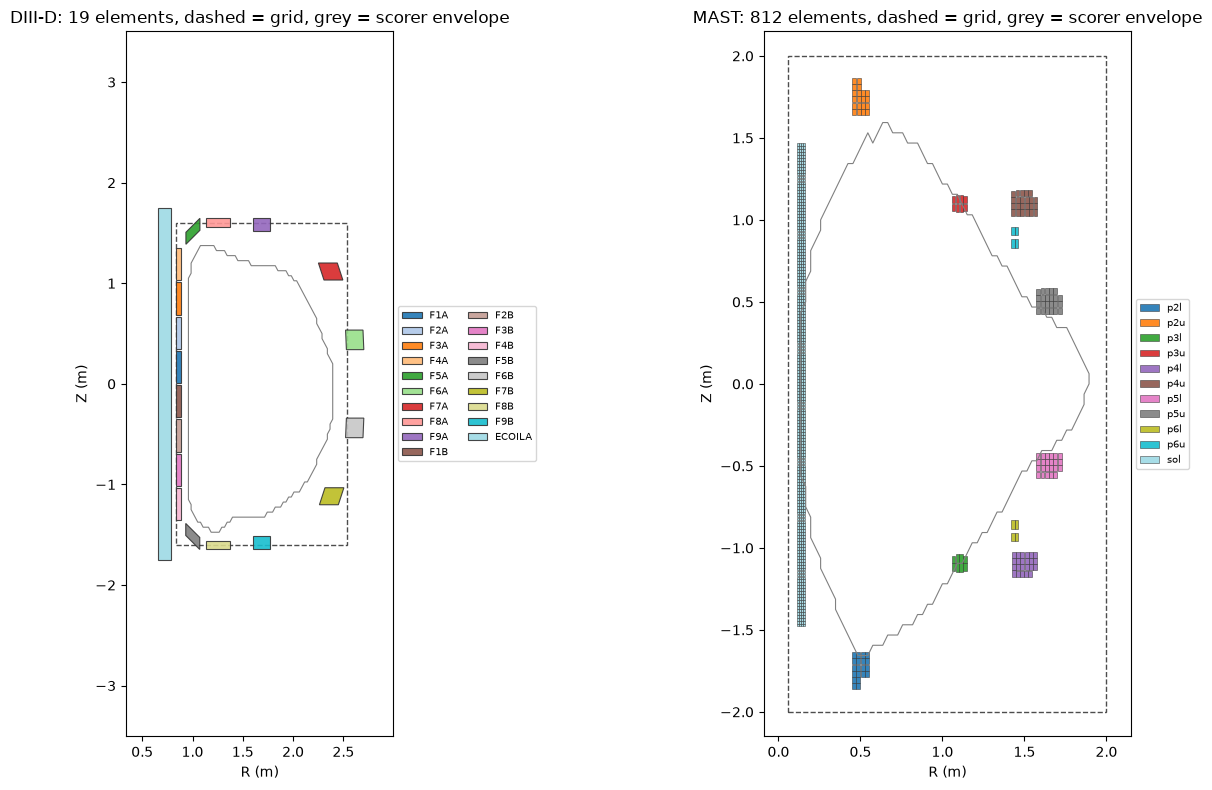

In [3]:
# One colour per current column, in table order, so the same column keeps its colour in every figure.
COLUMN_COLORS = {m: dict(zip(t.columns, plt.cm.tab20(np.linspace(0, 1, len(t.columns)))))
                 for m, t in TABLES.items()}


def draw_coils(ax, machine, lw=0.8, alpha=0.9, labels=True):
    # Draws every element outline of a machine on an (R, Z) axis, coloured by current column.
    geometry = GEOMETRY[machine]
    seen = set()
    for i in range(geometry.n_elements):
        column = geometry.input_columns[i]
        label = column.replace("magnetics_", "").replace("_current", "") if labels and column not in seen else None
        seen.add(column)
        corners = element_outline(geometry.r[i], geometry.z[i], geometry.width[i], geometry.height[i],
                                  geometry.angle1[i], geometry.angle2[i])
        ax.add_patch(Polygon(corners, closed=True, facecolor=COLUMN_COLORS[machine][column], edgecolor="0.2",
                             lw=lw, alpha=alpha, label=label))


def draw_grid(ax, machine):
    # Grid outline and the scorer's plasma envelope.
    t = TABLES[machine]
    env = starter_kit.envelope_mask(machine)
    ax.add_patch(Polygon([(t.grid_r[0], t.grid_z[0]), (t.grid_r[-1], t.grid_z[0]), (t.grid_r[-1], t.grid_z[-1]),
                          (t.grid_r[0], t.grid_z[-1])], closed=True, fill=False, edgecolor="0.3", lw=1.0, ls="--"))
    ax.contour(env.grid_R, env.grid_Z, env.mask_coarse.astype(float), levels=[0.5], colors="0.5", linewidths=0.8)


fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, machine in zip(axes, ("DIII-D", "MAST")):
    draw_grid(ax, machine)
    draw_coils(ax, machine, lw=0.4 if machine == "MAST" else 0.8)
    geometry = GEOMETRY[machine]
    pad = 0.15
    ax.set_xlim(min(geometry.r.min() - geometry.width.max(), TABLES[machine].grid_r[0]) - pad,
                max(geometry.r.max() + geometry.width.max(), TABLES[machine].grid_r[-1]) + pad)
    ax.set_ylim(min(geometry.z.min() - geometry.height.max() / 2, TABLES[machine].grid_z[0]) - pad,
                max(geometry.z.max() + geometry.height.max() / 2, TABLES[machine].grid_z[-1]) + pad)
    ax.set_aspect("equal")
    ax.set_xlabel("R (m)")
    ax.set_ylabel("Z (m)")
    ax.set_title(f"{machine}: {geometry.n_elements} elements, dashed = grid, grey = scorer envelope")
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=7, ncol=1 if machine == "MAST" else 2)
fig.tight_layout()

## 2. Single-frame subtraction (D3a)

Eight DIII-D training shots chosen from the frame table's shot index by
`coil_scales.reference_shots`: the first three in sorted id order with positive Ip at 20 kHz,
the first three with negative Ip, and the first two with positive Ip at 2 kHz, among shots with
at least 30 frames. Three frames per shot from `coil_scales.reference_frames` on the frame
table's `ip_over_peak`: the first frame at or above half the peak (rising), the middle of the
frames above 0.9 of the peak (mid flat-top) and the last frame at or above half the peak (late).

The recorded selection, from the frame table built on 6 October 2026:

| Kind | Shots |
| --- | --- |
| positive Ip, 20 kHz | `0011c2afc9`, `001270afa9`, `001cbcc9e6` |
| negative Ip | `00000a10ac`, `001bc5a4ae`, `003ac617f1` |
| positive Ip, 2 kHz | `00000c4a7b`, `0003ff34e7` |

The cell asserts that the selection on the current build equals this table, so a rebuilt
frame table that changes the reference set is noticed rather than silently used.

For every frame `coil_scales.analyze_frame` extracts the scorer's boundary from the true map,
takes the current density inside it with `delta_star`, orients the map so that this current
carries the sign of the measured Ip (the physical orientation: a positive-Ip plasma has its flux
maximum at the axis, a negative-Ip plasma its minimum), and evaluates the coil flux from the
frame's measured currents (`<column>__mean` of the frame table, the 2 ms windowed mean) at
scale 1 for every column, the DIII-D solenoid included. Both sides are then in the same frame
on both directions of Ip. Section 3 turns the per-frame orientations into the sign rule. The figures show, per frame, the oriented true
map, the coil flux and their difference, with the scorer's boundary, the stored axis and the
coil outlines. The question is whether the difference is a single smooth hill centred on the
axis with no structure localized at a coil.

In [4]:
RECORDED_SHOTS = {"positive_20khz": ["0011c2afc9", "001270afa9", "001cbcc9e6"],
                  "negative_ip": ["00000a10ac", "001bc5a4ae", "003ac617f1"],
                  "rate_2khz": ["00000c4a7b", "0003ff34e7"]}
REFERENCE_SHOTS = cs.reference_shots(index)
assert REFERENCE_SHOTS == RECORDED_SHOTS, f"selection changed: {REFERENCE_SHOTS}"
KIND_OF = {s: kind for kind, ids in REFERENCE_SHOTS.items() for s in ids}
KIND_LABEL = {"positive_20khz": "+Ip 20 kHz", "negative_ip": "-Ip", "rate_2khz": "+Ip 2 kHz"}
SHOT_IDS = list(KIND_OF)

shots_table = index[index["shot"].isin(SHOT_IDS)].set_index("shot").loc[SHOT_IDS]
shots_table = shots_table[["n_frames", "mag_rate_hz", "ip_direction", "ip_fix", "ip_shift_ms", "inputs_complete_frac"]]
shots_table.insert(0, "kind", [KIND_OF[s] for s in shots_table.index])
display(shots_table)

,kind,n_frames,mag_rate_hz,ip_direction,ip_fix,ip_shift_ms,inputs_complete_frac
shot,,,,,,,
0011c2afc9,positive_20khz,73,20000,1,organizers,-3275.2153,1.0
001270afa9,positive_20khz,252,20000,1,organizers,-3187.0247,1.0
001cbcc9e6,positive_20khz,253,20000,1,organizers,-3118.5566,1.0
00000a10ac,negative_ip,59,20000,-1,organizers,-3293.2090,1.0
001bc5a4ae,negative_ip,245,20000,-1,organizers,-3169.7397,1.0
003ac617f1,negative_ip,107,20000,-1,organizers,-3257.3330,1.0
00000c4a7b,rate_2khz,359,2000,1,alignment,-223.9129,1.0
0003ff34e7,rate_2khz,90,2000,1,alignment,-84.9129,1.0


In [5]:
# Frame-table name of every Green's-table column: the solenoid is "sol", shaping coils keep their names.
TABLE = TABLES["DIII-D"]
MEAN_COLUMNS = [("sol" if c == CFG.solenoid_column else c) + "__mean" for c in TABLE.columns]
LABELS = ["efit_times", "efit_psirz", "efit_grid_R", "efit_grid_Z", "efit_r_axis", "efit_z_axis"]

frames = read("diii_d_train", ["shot", "frame", "time_ms", "n_frames", "ip__mean", "ip_over_peak",
                               "inputs_complete", *MEAN_COLUMNS], SHOT_IDS)
ANALYSES, rows = {}, []
started = time.time()
for shot_id in SHOT_IDS:
    f = frames[frames["shot"] == shot_id].sort_values("frame").reset_index(drop=True)
    assert (f["frame"].to_numpy() == np.arange(len(f))).all()
    chosen = cs.reference_frames(f["ip_over_peak"].to_numpy())
    shot = io.load_shot(dataset.shot_path(DATA_ROOT, "diii_d_train", shot_id), LABELS, apply=False)
    grid_r, grid_z = np.asarray(shot["efit_grid_R"], float), np.asarray(shot["efit_grid_Z"], float)
    assert np.allclose(grid_r, TABLE.grid_r) and np.allclose(grid_z, TABLE.grid_z)
    psi = np.asarray(shot["efit_psirz"], float)
    assert psi.shape[0] == len(f) and np.allclose(np.asarray(shot["efit_times"], float), f["time_ms"])
    for phase, k in chosen.items():
        row = f.iloc[k]
        assert bool(row["inputs_complete"]), f"{shot_id} frame {k}: a current is missing"
        currents = row[MEAN_COLUMNS].to_numpy(dtype=np.float64)
        a = cs.analyze_frame(psi[k], grid_r, grid_z, CFG, ENV, TABLE, currents, float(row["ip__mean"]),
                             NEAR_COIL, SCORER)
        ANALYSES[(shot_id, phase)] = a
        rows.append({"shot": shot_id, "kind": KIND_OF[shot_id], "phase": phase, "frame": int(k),
                     "time_ms": float(row["time_ms"]), "ip_ka": float(row["ip__mean"]),
                     "ip_over_peak": float(row["ip_over_peak"]), "sol_ka": float(row["sol__mean"]),
                     "r_axis": float(shot["efit_r_axis"][k]), "z_axis": float(shot["efit_z_axis"][k]),
                     "boundary_found": a.boundary_found, "orientation": a.orientation,
                     "current_ka": a.current_a / 1000.0, "current_ratio": a.ratio, "flux_range": a.flux_range,
                     "n_inside": int(a.inside.sum()), "n_fit_nodes": int(a.fit_mask.sum()),
                     "n_near_coil_nodes": int(a.near_coil_mask.sum()),
                     "rms_coil_fit": cs.rms_fraction(a.target, a.coil_total, a.fit_mask, a.flux_range),
                     "rms_coil_near": cs.rms_fraction(a.target, a.coil_total, a.near_coil_mask, a.flux_range),
                     "rms_zero_fit": cs.rms_fraction(a.target, np.zeros_like(a.target), a.fit_mask, a.flux_range)})
FRAMES = pd.DataFrame(rows)
print(f"{len(FRAMES)} frames analysed in {time.time() - started:.1f} s; boundary found on {int(FRAMES['boundary_found'].sum())}")
display(FRAMES[["shot", "kind", "phase", "frame", "time_ms", "ip_ka", "ip_over_peak", "sol_ka", "boundary_found",
                "orientation", "n_inside", "n_fit_nodes"]])

24 frames analysed in 1.5 s; boundary found on 24


,shot,kind,phase,frame,time_ms,ip_ka,ip_over_peak,sol_ka,boundary_found,orientation,n_inside,n_fit_nodes
0,0011c2afc9,positive_20khz,rising,2,280.0,508.9091,0.5199,34.4821,True,-1.0,1430,2344
1,0011c2afc9,positive_20khz,flat_top,42,1100.0,979.5575,1.0007,7.3657,True,-1.0,1289,2485
2,0011c2afc9,positive_20khz,late,72,1720.0,549.8019,0.5617,6.7666,True,-1.0,1184,2590
3,001270afa9,positive_20khz,rising,3,160.0,506.1626,0.5051,28.7133,True,-1.0,1475,2299
4,001270afa9,positive_20khz,flat_top,102,2180.0,996.3419,0.9942,-12.1916,True,-1.0,1290,2484
5,001270afa9,positive_20khz,late,251,6040.0,517.8735,0.5167,-19.2967,True,-1.0,1259,2515
6,001cbcc9e6,positive_20khz,rising,0,500.0,757.3556,0.7528,5.9855,True,-1.0,1489,2285
7,001cbcc9e6,positive_20khz,flat_top,129,3100.0,994.8160,0.9889,-11.5922,True,-1.0,1207,2567
8,001cbcc9e6,positive_20khz,late,252,5600.0,888.9220,0.8836,-29.0912,True,-1.0,1330,2444
9,00000a10ac,negative_ip,rising,1,200.0,-573.8340,0.5699,-43.6248,True,1.0,1393,2381


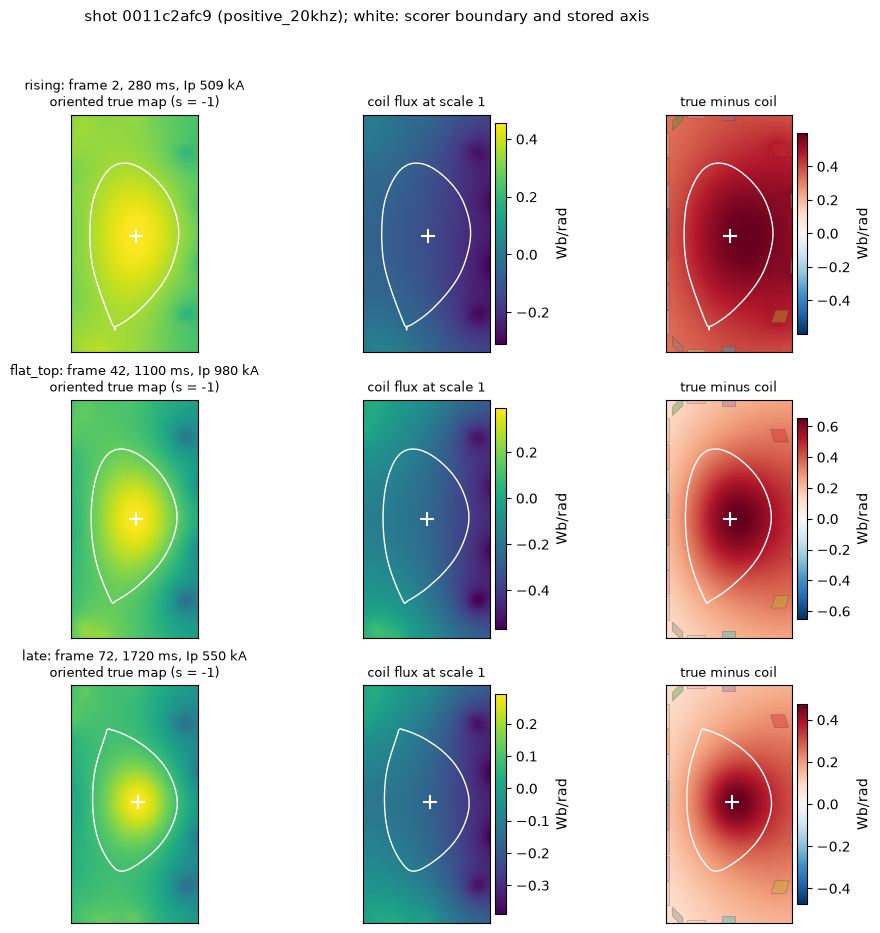

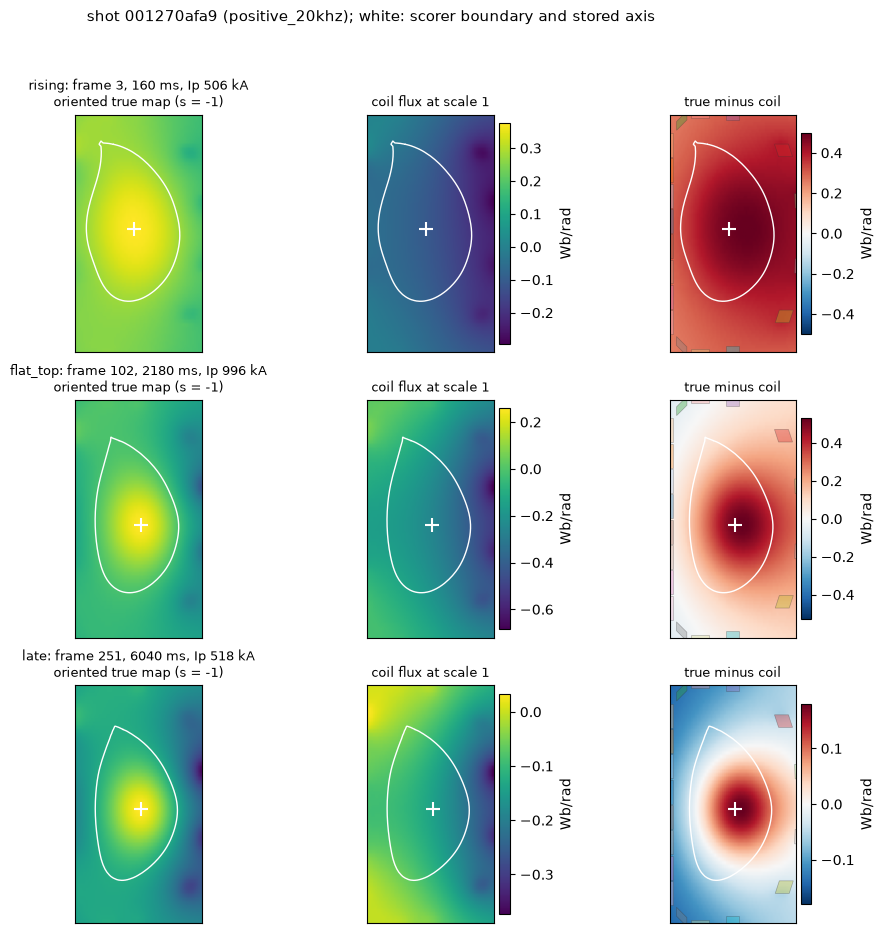

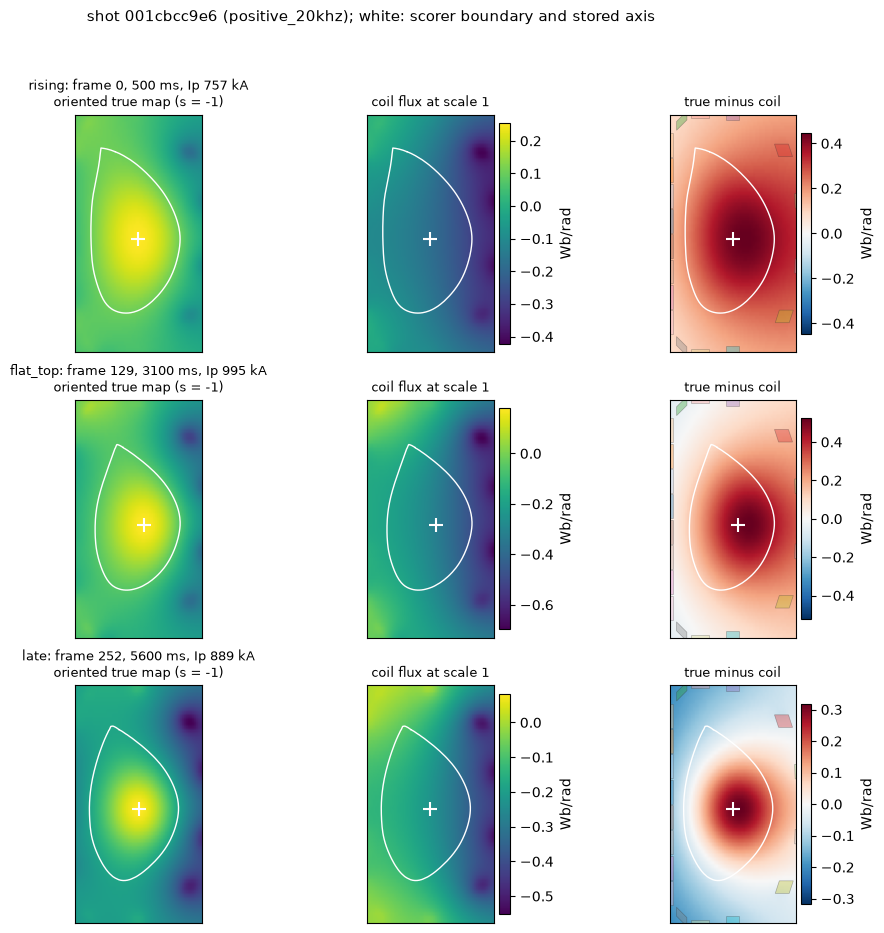

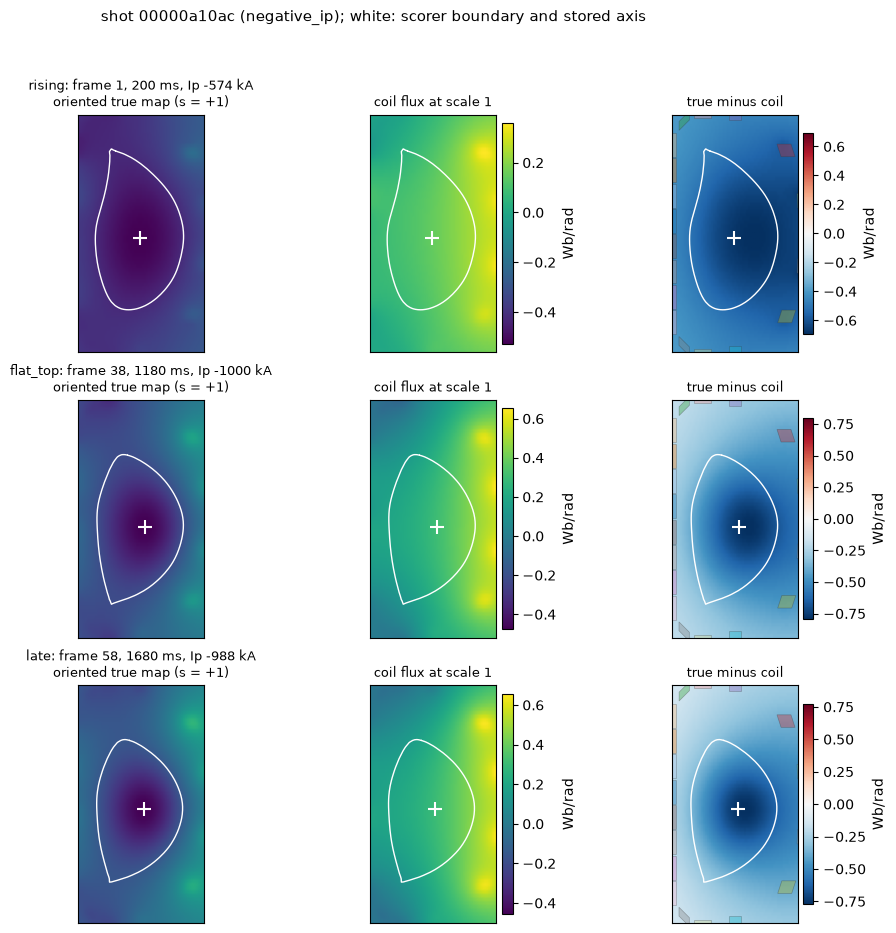

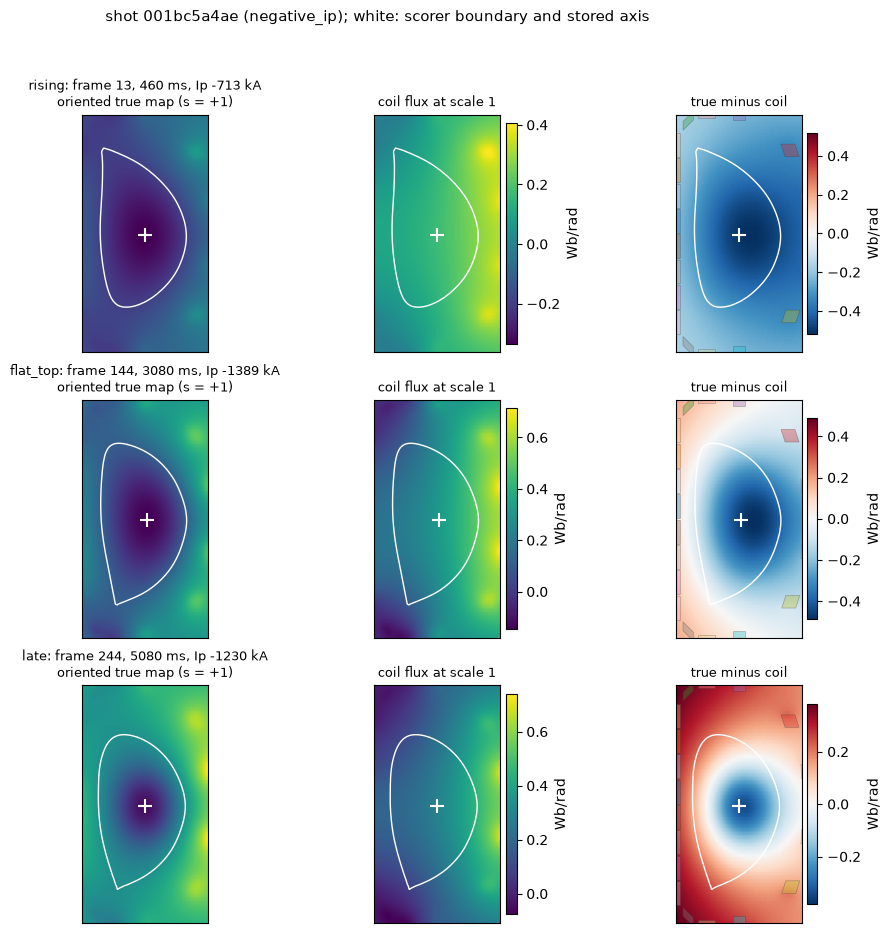

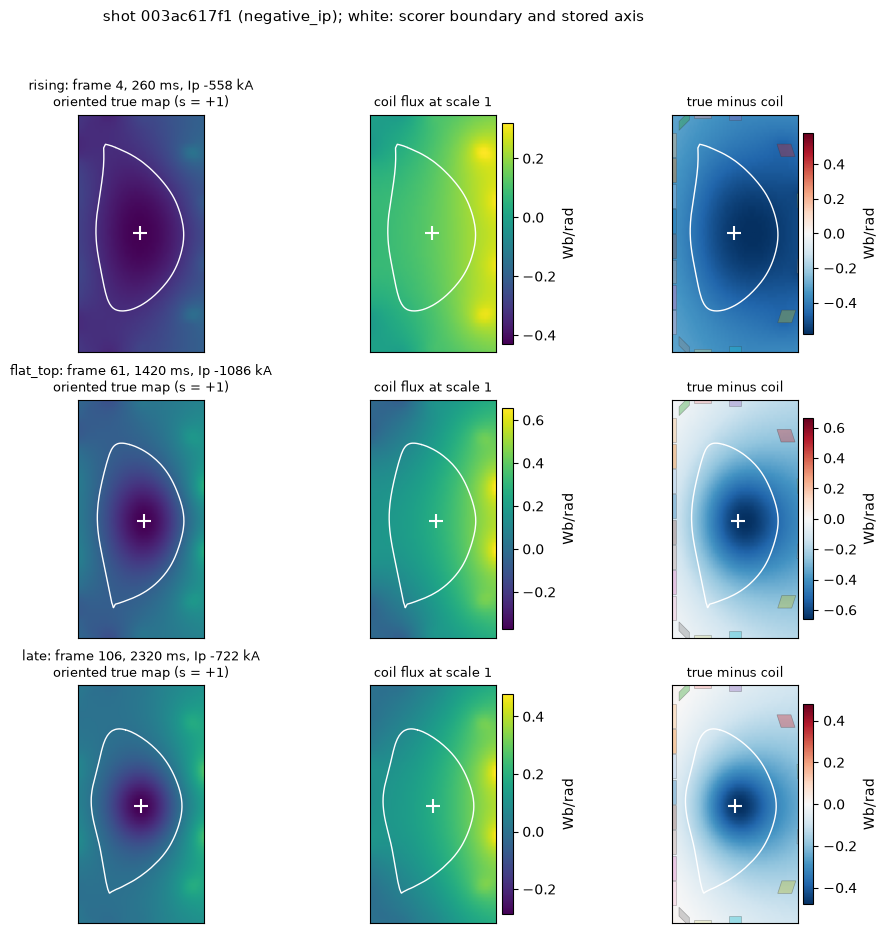

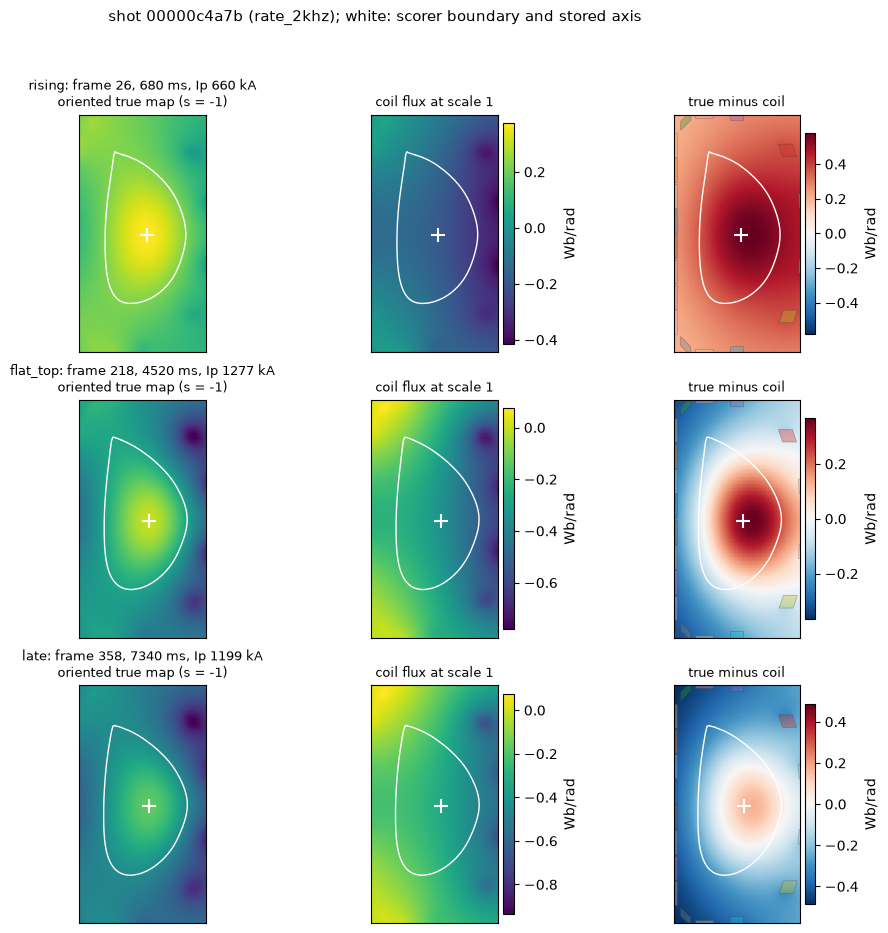

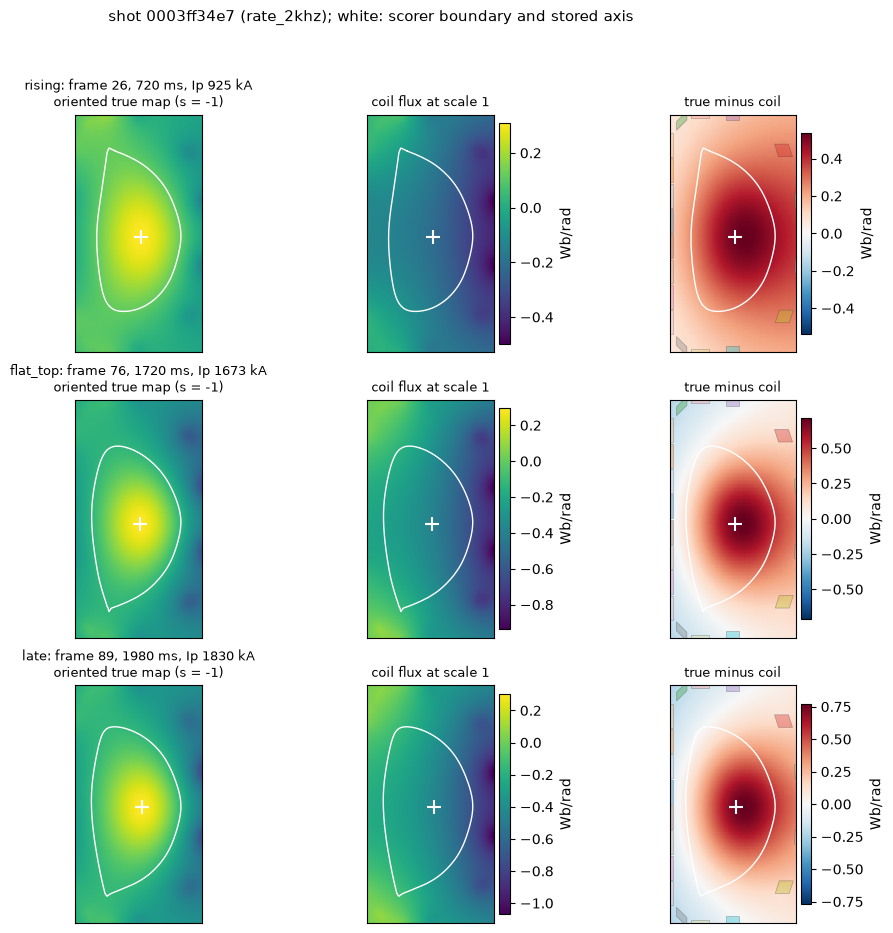

In [6]:
def draw_boundary_and_axis(ax, a, row):
    if a.contour is not None:
        ax.plot(a.contour[:, 0], a.contour[:, 1], color="white", lw=1.0)
    ax.plot(row["r_axis"], row["z_axis"], "+", color="white", ms=10, mew=1.5)


def show_map(ax, values, grid_r, grid_z, title, cmap, vmin, vmax):
    im = ax.imshow(values, origin="lower", extent=(grid_r[0], grid_r[-1], grid_z[0], grid_z[-1]), cmap=cmap,
                   vmin=vmin, vmax=vmax, aspect="equal")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    return im


def plot_shot(shot_id):
    grid_r, grid_z = TABLE.grid_r, TABLE.grid_z
    fig, axes = plt.subplots(3, 3, figsize=(11, 10.5))
    for r, phase in enumerate(cs.REFERENCE_PHASES):
        a = ANALYSES[(shot_id, phase)]
        row = FRAMES[(FRAMES["shot"] == shot_id) & (FRAMES["phase"] == phase)].iloc[0]
        true, coil = a.oriented_psi, a.coil_total
        diff = true - coil
        lo, hi = min(true.min(), coil.min()), max(true.max(), coil.max())
        im0 = show_map(axes[r, 0], true, grid_r, grid_z,
                       f"{phase}: frame {row['frame']}, {row['time_ms']:.0f} ms, Ip {row['ip_ka']:.0f} kA\n"
                       f"oriented true map (s = {a.orientation:+.0f})", "viridis", lo, hi)
        show_map(axes[r, 1], coil, grid_r, grid_z, "coil flux at scale 1", "viridis", lo, hi)
        span = float(np.abs(diff).max())
        im2 = show_map(axes[r, 2], diff, grid_r, grid_z, "true minus coil", "RdBu_r", -span, span)
        for ax in axes[r]:
            draw_boundary_and_axis(ax, a, row)
        draw_coils(axes[r, 2], "DIII-D", lw=0.5, alpha=0.35, labels=False)
        axes[r, 2].set_xlim(grid_r[0], grid_r[-1])
        axes[r, 2].set_ylim(grid_z[0], grid_z[-1])
        fig.colorbar(im0, ax=axes[r, :2].tolist(), fraction=0.02, pad=0.01, label="Wb/rad")
        fig.colorbar(im2, ax=axes[r, 2], fraction=0.04, pad=0.02, label="Wb/rad")
    fig.suptitle(f"shot {shot_id} ({KIND_OF[shot_id]}); white: scorer boundary and stored axis", fontsize=11)
    return fig


for shot_id in SHOT_IDS:
    plot_shot(shot_id)
plt.show()

## 3. Current consistency (D3b)

Three numbers per frame, none with a free parameter.

- **K3, total current.** The current density `J = -delta_star(psi) / (mu0 R)` of the stored
  map, integrated over the nodes inside the scorer's boundary, divided by the measured Ip. Its
  magnitude should be close to 1 (the conservative stencil loses some current at the boundary
  cells, and the boundary polygon is not the EFIT separatrix exactly). Its sign, against the
  sign of Ip, is the orientation evidence.
- **K4, sign rule.** One rule `psi_physical = c * sign(Ip) * psi_stored` with the same `c` on
  every shot. `c` per shot is `sign(ratio) * sign(Ip)`, the sign of the current the stored map
  carries; the rule holds when it is the same on all eight shots. The per-frame orientation of
  section 2, `sign(ratio)`, then equals `c * sign(Ip)` on every frame.
- **K5, agreement outside the plasma.** The plasma's own flux at the nodes outside the boundary
  is computed from the current density inside it (`flux_from_current`) and subtracted from the
  oriented true map. What is left must be the coil flux. The root-mean-square difference
  between that remainder and the calculated coil flux at scale 1, as a fraction of the frame's
  flux range, is reported on the nodes away from the coils (`rms_coil_fit`) and on the nodes
  within one cell of a coil outline (`rms_coil_near`). `rms_zero_fit` is the same quantity with
  no coil flux at all, the reference for how much the calculation explains.

The DIII-D solenoid enters at scale 1 under the `per_element` convention (one lumped element,
one turn), which the data dictionary marks as the open turn convention. A large K5 with a
difference map concentrated at the solenoid is the expected signature of that, and section 4
fits it; a difference concentrated at a shaping coil is not expected and would point at the
geometry, the units or the skew convention.

In [7]:
# K3: integrated current against Ip, per frame and per shot.
k3 = FRAMES[["shot", "kind", "phase", "frame", "ip_ka", "current_ka", "current_ratio", "orientation", "n_inside"]]
display(k3)
per_shot = FRAMES.groupby("shot", sort=False).agg(kind=("kind", "first"), ip_ka=("ip_ka", "median"),
                                                  ratio=("current_ratio", "median"),
                                                  ratio_min=("current_ratio", "min"), ratio_max=("current_ratio", "max"),
                                                  orientation=("orientation", lambda s: sorted(set(s))))
display(per_shot)
q = FRAMES["current_ratio"].abs().quantile([0.05, 0.5, 0.95])
print(f"K3 (review): |ratio| p05/p50/p95 over the {len(FRAMES)} frames: "
      f"{q.iloc[0]:.3f} / {q.iloc[1]:.3f} / {q.iloc[2]:.3f}")

,shot,kind,phase,frame,ip_ka,current_ka,current_ratio,orientation,n_inside
0,0011c2afc9,positive_20khz,rising,2,508.9091,-518.9320,-1.0197,-1.0,1430
1,0011c2afc9,positive_20khz,flat_top,42,979.5575,-980.5222,-1.0010,-1.0,1289
2,0011c2afc9,positive_20khz,late,72,549.8019,-549.1068,-0.9987,-1.0,1184
3,001270afa9,positive_20khz,rising,3,506.1626,-488.0436,-0.9642,-1.0,1475
4,001270afa9,positive_20khz,flat_top,102,996.3419,-991.8069,-0.9954,-1.0,1290
5,001270afa9,positive_20khz,late,251,517.8735,-514.8619,-0.9942,-1.0,1259
6,001cbcc9e6,positive_20khz,rising,0,757.3556,-757.9318,-1.0008,-1.0,1489
7,001cbcc9e6,positive_20khz,flat_top,129,994.8160,-990.0725,-0.9952,-1.0,1207
8,001cbcc9e6,positive_20khz,late,252,888.9220,-877.0378,-0.9866,-1.0,1330
9,00000a10ac,negative_ip,rising,1,-573.8340,-583.5845,1.0170,1.0,1393


,kind,ip_ka,ratio,ratio_min,ratio_max,orientation
shot,,,,,,
0011c2afc9,positive_20khz,549.8019,-1.0010,-1.0197,-0.9987,[-1.0]
001270afa9,positive_20khz,517.8735,-0.9942,-0.9954,-0.9642,[-1.0]
001cbcc9e6,positive_20khz,888.9220,-0.9952,-1.0008,-0.9866,[-1.0]
00000a10ac,negative_ip,-988.0259,1.0059,0.9974,1.0170,[1.0]
001bc5a4ae,negative_ip,-1230.4072,0.9972,0.9893,1.0034,[1.0]
003ac617f1,negative_ip,-721.8414,0.9985,0.9970,1.0019,[1.0]
00000c4a7b,rate_2khz,1199.2314,-0.9946,-1.0101,-0.9917,[-1.0]
0003ff34e7,rate_2khz,1672.7217,-0.9987,-0.9994,-0.9948,[-1.0]


K3 (review): |ratio| p05/p50/p95 over the 24 frames: 0.987 / 0.998 / 1.016


In [8]:
# K4: the sign rule across the eight shots, and the orientation against the scorer's axis sign.
rule = cs.sign_rule(per_shot["ratio"], per_shot["ip_ka"])
print(f"K4 ({'pass' if rule['consistent'] else 'fail'}): psi_physical = {rule['c']:+d} x sign(Ip) x psi_stored "
      f"on {rule['n_shots']} shots ({rule['n_positive_ip']} positive Ip, {rule['n_negative_ip']} negative Ip); "
      f"sign of the ratio by Ip direction: {rule['ratio_sign_by_direction']}")
orientations = sorted(set(FRAMES["orientation"]))
print(f"per-frame orientation values: {orientations}; scorer AXIS_SIGN for DIII-D: {CFG.axis_sign:+.0f}")
under_rule = FRAMES["ip_ka"].map(lambda ip: cs.orientation_from_rule(rule["c"], ip))
print(f"frames whose orientation equals the rule's c x sign(Ip): {int((FRAMES['orientation'] == under_rule).sum())} of {len(FRAMES)}")
print("Reading: the stored current has one sign on every shot (the axis is always at the stored minimum, F14), "
      "so c is that sign. c = -1 means a positive-Ip shot is stored sign-flipped and a negative-Ip shot as it "
      "is; the scorer's AXIS_SIGN then agrees with the orientation of positive-Ip shots only.")

K4 (pass): psi_physical = -1 x sign(Ip) x psi_stored on 8 shots (5 positive Ip, 3 negative Ip); sign of the ratio by Ip direction: {1: [-1], -1: [1]}
per-frame orientation values: [-1.0, 1.0]; scorer AXIS_SIGN for DIII-D: -1
frames whose orientation equals the rule's c x sign(Ip): 24 of 24
Reading: the stored current has one sign on every shot (the axis is always at the stored minimum, F14), so c is that sign. c = -1 means a positive-Ip shot is stored sign-flipped and a negative-Ip shot as it is; the scorer's AXIS_SIGN then agrees with the orientation of positive-Ip shots only.


In [9]:
# K5: agreement outside the plasma at scale 1, by phase, by kind and per frame.
k5_cols = ["rms_coil_fit", "rms_coil_near", "rms_zero_fit"]
display(FRAMES[["shot", "kind", "phase", "ip_over_peak", "flux_range", "n_fit_nodes", "n_near_coil_nodes", *k5_cols]])
print("K5 (review): median rms / flux range by phase")
display(FRAMES.groupby("phase", sort=False)[k5_cols].median())
print("by kind of shot")
display(FRAMES.groupby("kind", sort=False)[k5_cols].median())
flat = FRAMES[FRAMES["phase"] == "flat_top"]
print(f"flat-top frames: median rms away from coils {flat['rms_coil_fit'].median():.4f} of the flux range "
      f"(threshold for 'viable with at most the solenoid fitted': a few percent, docs/COIL_FLUX.md); "
      f"without any coil flux {flat['rms_zero_fit'].median():.4f}")

,shot,kind,phase,ip_over_peak,flux_range,n_fit_nodes,n_near_coil_nodes,rms_coil_fit,rms_coil_near,rms_zero_fit
0,0011c2afc9,positive_20khz,rising,0.5199,0.2652,2344,451,1.1869,1.1816,0.7674
1,0011c2afc9,positive_20khz,flat_top,1.0007,0.6033,2485,451,0.1300,0.1288,0.3426
2,0011c2afc9,positive_20khz,late,0.5617,0.4279,2590,451,0.1358,0.1351,0.3156
3,001270afa9,positive_20khz,rising,0.5051,0.2513,2299,451,0.9778,0.9709,0.5708
4,001270afa9,positive_20khz,flat_top,0.9942,0.6835,2484,451,0.1557,0.1560,0.5305
5,001270afa9,positive_20khz,late,0.5167,0.3953,2515,451,0.4319,0.4308,0.7658
6,001cbcc9e6,positive_20khz,rising,0.7528,0.4301,2285,451,0.1119,0.1101,0.3863
7,001cbcc9e6,positive_20khz,flat_top,0.9889,0.7026,2567,451,0.1450,0.1449,0.6086
8,001cbcc9e6,positive_20khz,late,0.8836,0.6353,2444,451,0.3900,0.3879,0.7643
9,00000a10ac,negative_ip,rising,0.5699,0.3139,2381,451,1.2369,1.2288,0.8073


K5 (review): median rms / flux range by phase


,rms_coil_fit,rms_coil_near,rms_zero_fit
phase,,,
rising,0.7387,0.7341,0.5190
flat_top,0.1980,0.1973,0.5695
late,0.3516,0.3503,0.7549


by kind of shot


,rms_coil_fit,rms_coil_near,rms_zero_fit
kind,,,
positive_20khz,0.1557,0.1560,0.5708
negative_ip,0.3431,0.3390,0.4781
rate_2khz,0.4063,0.4049,0.7480


flat-top frames: median rms away from coils 0.1980 of the flux range (threshold for 'viable with at most the solenoid fitted': a few percent, docs/COIL_FLUX.md); without any coil flux 0.5695


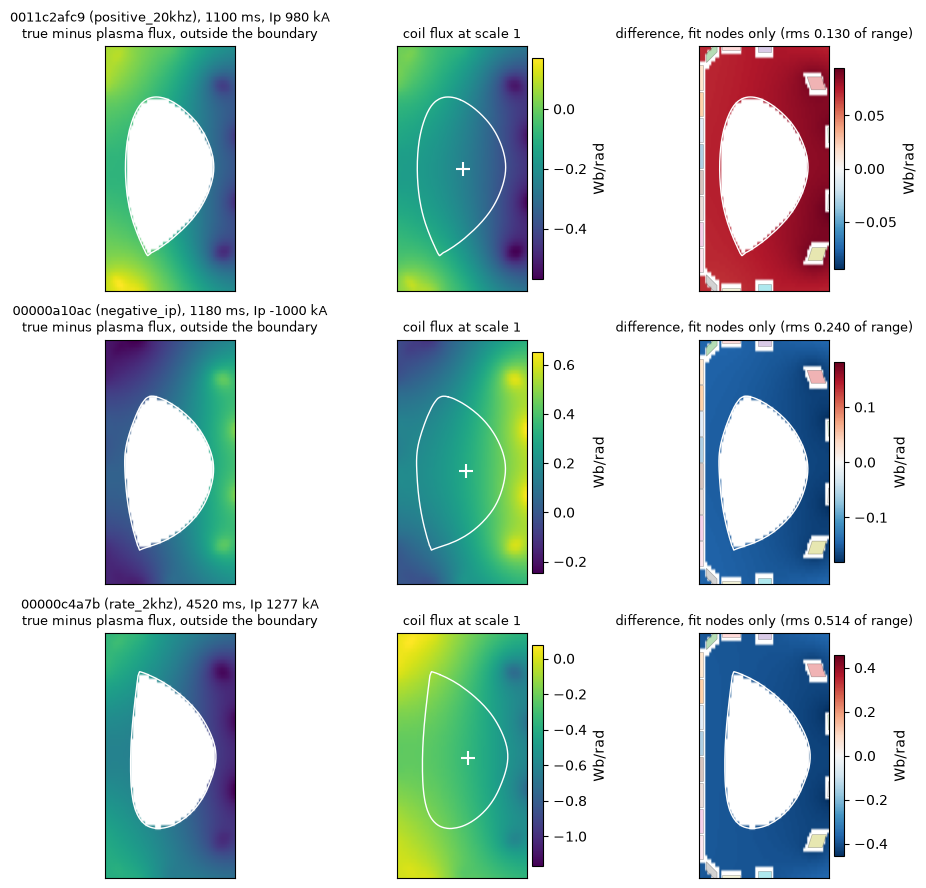

In [10]:
# Where the disagreement sits: one flat-top frame per kind. Left, the remainder of the true map after the
# plasma's own flux is removed (NaN inside the boundary); middle, the coil flux at scale 1; right, their
# difference with the near-coil nodes masked and the coil outlines drawn.
grid_r, grid_z = TABLE.grid_r, TABLE.grid_z
first_of_kind = [ids[0] for ids in REFERENCE_SHOTS.values()]
fig, axes = plt.subplots(len(first_of_kind), 3, figsize=(11, 3.6 * len(first_of_kind)))
for r, shot_id in enumerate(first_of_kind):
    a = ANALYSES[(shot_id, "flat_top")]
    row = FRAMES[(FRAMES["shot"] == shot_id) & (FRAMES["phase"] == "flat_top")].iloc[0]
    target = np.where(a.inside, np.nan, a.target)
    diff = np.where(a.fit_mask, a.target - a.coil_total, np.nan)
    lo, hi = np.nanmin([target, a.coil_total]), np.nanmax([target, a.coil_total])
    im0 = show_map(axes[r, 0], target, grid_r, grid_z,
                   f"{shot_id} ({KIND_OF[shot_id]}), {row['time_ms']:.0f} ms, Ip {row['ip_ka']:.0f} kA\n"
                   "true minus plasma flux, outside the boundary", "viridis", lo, hi)
    show_map(axes[r, 1], a.coil_total, grid_r, grid_z, "coil flux at scale 1", "viridis", lo, hi)
    span = float(np.nanmax(np.abs(diff)))
    im2 = show_map(axes[r, 2], diff, grid_r, grid_z,
                   f"difference, fit nodes only (rms {row['rms_coil_fit']:.3f} of range)", "RdBu_r", -span, span)
    for ax in axes[r]:
        draw_boundary_and_axis(ax, a, row)
    draw_coils(axes[r, 2], "DIII-D", lw=0.5, alpha=0.35, labels=False)
    axes[r, 2].set_xlim(grid_r[0], grid_r[-1])
    axes[r, 2].set_ylim(grid_z[0], grid_z[-1])
    fig.colorbar(im0, ax=axes[r, :2].tolist(), fraction=0.02, pad=0.01, label="Wb/rad")
    fig.colorbar(im2, ax=axes[r, 2], fraction=0.04, pad=0.02, label="Wb/rad")
plt.show()

,shot,kind,phase,ip_ka,sol_ka,slope,offset_x_sign_ip_over_range,slope_without_sol,offset_without_sol_x_sign_ip_over_range,offset_wb_per_sol_ka
0,0011c2afc9,positive_20khz,rising,508.9091,34.4821,0.8337,1.1090,0.8332,1.1075,0.0085
1,0011c2afc9,positive_20khz,flat_top,979.5575,7.3657,0.9621,0.1152,0.9621,0.1152,0.0094
2,0011c2afc9,positive_20khz,late,549.8019,6.7666,0.9645,0.1229,0.9645,0.1228,0.0078
3,001270afa9,positive_20khz,rising,506.1626,28.7133,0.8500,0.9077,0.8496,0.9065,0.0079
4,001270afa9,positive_20khz,flat_top,996.3419,-12.1916,1.0130,-0.1514,1.0130,-0.1514,0.0085
5,001270afa9,positive_20khz,late,517.8735,-19.2967,1.0680,-0.4111,1.0679,-0.4113,0.0084
6,001cbcc9e6,positive_20khz,rising,757.3556,5.9855,0.9662,0.0974,0.9661,0.0974,0.0070
7,001cbcc9e6,positive_20khz,flat_top,994.8160,-11.5922,1.0126,-0.1397,1.0126,-0.1398,0.0085
8,001cbcc9e6,positive_20khz,late,888.9220,-29.0912,1.0580,-0.3700,1.0579,-0.3702,0.0081
9,00000a10ac,negative_ip,rising,-573.8340,-43.6248,0.8085,1.1465,0.8079,1.1446,0.0082


medians by phase


,slope,offset_x_sign_ip_over_range,slope_without_sol,offset_without_sol_x_sign_ip_over_range,offset_wb_per_sol_ka
phase,,,,,
rising,0.8853,0.6845,0.8850,0.6838,0.0083
flat_top,1.0128,-0.1456,1.0128,-0.1456,0.0085
late,1.0461,-0.3348,1.0460,-0.3350,0.0084


medians by kind


,slope,offset_x_sign_ip_over_range,slope_without_sol,offset_without_sol_x_sign_ip_over_range,offset_wb_per_sol_ka
kind,,,,,
positive_20khz,0.9662,0.0974,0.9661,0.0974,0.0084
negative_ip,0.9684,0.1292,0.9683,0.1292,0.0084
rate_2khz,1.0332,-0.2966,1.0332,-0.2967,0.0084


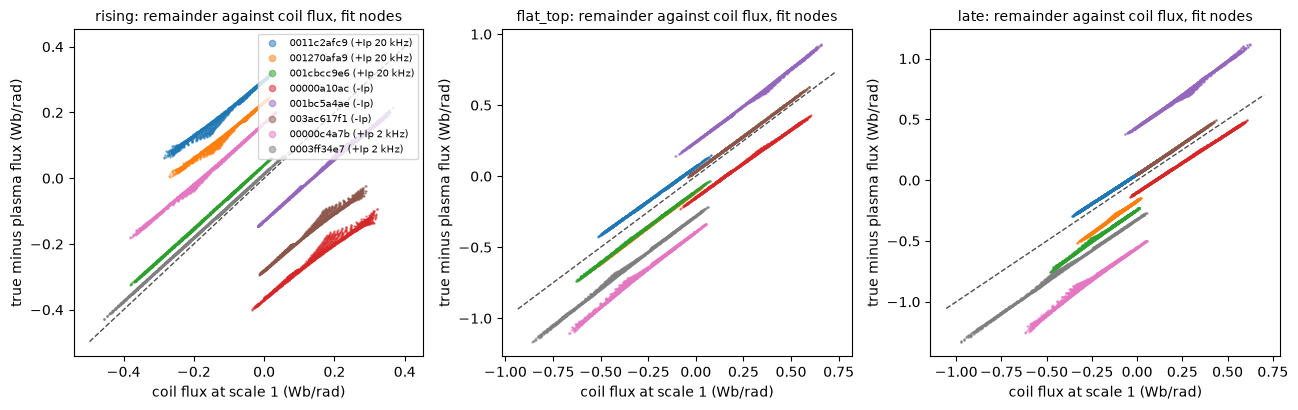

In [11]:
# Scale and offset hints for section 4: a straight line through (coil flux, remainder) on the fit nodes of
# every frame. A slope away from 1 with a small offset points at a column scale; an offset alone at flux
# that the calculation does not contain. The offset is multiplied by the sign of Ip so that an offset that
# reverses with the discharge (one tied to the currents) keeps one sign across the shots. The solenoid is
# separated because its scale is the open question: slope and offset are also fitted with its pattern
# removed from both sides, which shows how much of the fit the one-turn solenoid pattern carries. The
# offset per kA of solenoid current is listed because a long solenoid's external flux per radian is nearly
# uniform over the grid: an offset proportional to the solenoid current is what a missing turn count looks like.
sol = TABLE.column_index([CFG.solenoid_column])[0]
hints = []
for (shot_id, phase), a in ANALYSES.items():
    row = FRAMES[(FRAMES["shot"] == shot_id) & (FRAMES["phase"] == phase)].iloc[0]
    sign_ip = 1.0 if row["ip_ka"] >= 0 else -1.0
    m = a.fit_mask
    x, y = a.coil_total[m], a.target[m]
    slope, offset = np.polyfit(x, y, 1)
    x_no_sol = (a.coil_total - a.coil_maps[sol])[m]
    slope_ns, offset_ns = np.polyfit(x_no_sol, y - a.coil_maps[sol][m], 1)
    hints.append({"shot": shot_id, "kind": KIND_OF[shot_id], "phase": phase, "ip_ka": row["ip_ka"], "sol_ka": row["sol_ka"],
                  "slope": slope, "offset_x_sign_ip_over_range": sign_ip * offset / a.flux_range,
                  "slope_without_sol": slope_ns, "offset_without_sol_x_sign_ip_over_range": sign_ip * offset_ns / a.flux_range,
                  "offset_wb_per_sol_ka": offset / row["sol_ka"] if row["sol_ka"] != 0 else np.nan})
HINTS = pd.DataFrame(hints)
display(HINTS)
hint_cols = ["slope", "offset_x_sign_ip_over_range", "slope_without_sol", "offset_without_sol_x_sign_ip_over_range",
             "offset_wb_per_sol_ka"]
print("medians by phase")
display(HINTS.groupby("phase", sort=False)[hint_cols].median())
print("medians by kind")
display(HINTS.groupby("kind", sort=False)[hint_cols].median())

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, phase in zip(axes, cs.REFERENCE_PHASES):
    for shot_id in SHOT_IDS:
        a = ANALYSES[(shot_id, phase)]
        m = a.fit_mask
        ax.plot(a.coil_total[m], a.target[m], ".", ms=1.5, alpha=0.5, label=f"{shot_id} ({KIND_LABEL[KIND_OF[shot_id]]})")
    lim = ax.get_xlim()
    ax.plot(lim, lim, color="0.3", lw=1, ls="--")
    ax.set_title(f"{phase}: remainder against coil flux, fit nodes", fontsize=10)
    ax.set_xlabel("coil flux at scale 1 (Wb/rad)")
    ax.set_ylabel("true minus plasma flux (Wb/rad)")
axes[0].legend(fontsize=7, markerscale=6)
fig.tight_layout()

## 4. Coil scales (D4)

`scripts/fit_coil_scales.py` fitted the remainder outside the plasma over 50 DIII-D training
shots (20 frames each, 996 frames) in eight variants (`coil_scales.standard_variants`) and
wrote `reports/coil_flux/`. Every variant is a linear model of the remainder at a node:

| Variant | Shaping coils | Solenoid | Per-frame constant |
| --- | --- | --- | --- |
| `per_coil` | one scale each | pattern, own scale | no |
| `per_coil_constant` | one scale each | pattern, own scale | yes |
| `solenoid_only` | 1 | pattern, own scale | no |
| `solenoid_only_constant` | 1 | pattern, own scale | yes |
| `shared_plus_solenoid` | one shared scale | pattern, own scale | no |
| `shared_plus_solenoid_constant` | one shared scale | pattern, own scale | yes |
| `solenoid_flat` | 1 | flat term `a x I_sol`, the same at every node | no |
| `solenoid_flat_plus_pattern` | 1 | flat term `a x I_sol` plus pattern `b x G_sol x I_sol` | no |

The two flat variants stand for the picture of section 3: a long solenoid's external flux
is nearly uniform over the grid, so a flat term proportional to the solenoid current is the
natural shape of what the one-turn rectangle pattern misses. Their coefficients are one
number for all frames, unlike the per-frame constant of the `*_constant` variants, which the
fit eliminates frame by frame (centring) and which can absorb anything that is uniform over
a frame. The adopted DIII-D coil model and the report's K5 headline is **`solenoid_flat`**:
the median over the fit shots' flat-top frames of the root-mean-square difference between the
remainder and the model on the nodes away from the coils, as a fraction of the frame's flux
range. The same model is checked on validation shots of the provisional split that took no
part in the fit. The script evaluates every variant on every frame from the frame's normal
equations, so this section only reads its outputs: `coil_scales.parquet` (coefficients),
`k5_by_phase.parquet` (K5 quantiles), `coil_frames.parquet` (per-frame rms and mean
residual per variant) and `scales/d3d_<variant>.json` (the `CoilScales` record that
`GreenTable.flux` applies, with the flat term as `flat_wb_per_ka`). The adopted record is
also the package resource `fusion_eq/resources/coil_scales_d3d.json`, which `coil_flux`
loads by default for DIII-D; the cell checks that the two agree.

In [12]:
from fusion_eq.coil_flux import CoilScales

REPORT_DIR = Path("../reports/coil_flux")
FIT = json.loads((REPORT_DIR / "fit.json").read_text())
FRAMES_FIT = pd.read_parquet(REPORT_DIR / "coil_frames.parquet")
SCALES_FIT = pd.read_parquet(REPORT_DIR / "coil_scales.parquet")
K5_FIT = pd.read_parquet(REPORT_DIR / "k5_by_phase.parquet")
RATIOS = pd.read_parquet(REPORT_DIR / "reference_ratios.parquet")
VARIANTS = list(FIT["variants"])
HEADLINE = FIT["headline_variant"]
COIL_SCALES = {v: CoilScales.load(REPORT_DIR / "scales" / f"d3d_{v}.json") for v in VARIANTS}
assert FIT["geometry_hash"] == TABLE.geometry_hash, "the fit used another Green's table"
assert FIT["reference_shots"] == REFERENCE_SHOTS, "the fit used other reference shots"
assert set(FRAMES_FIT.loc[FRAMES_FIT["split"] == "reference", "shot"]) == set(SHOT_IDS)
from fusion_eq.coil_flux import adopted_scales
ADOPTED = adopted_scales("DIII-D", TABLE.columns)
assert np.allclose(ADOPTED.vector(TABLE.columns), COIL_SCALES[HEADLINE].vector(TABLE.columns)) and     abs(ADOPTED.flat_wb_per_ka - COIL_SCALES[HEADLINE].flat_wb_per_ka) < 1e-9, "the package resource is not this fit's adopted model"
RULE_C = FIT["sign_rule"]["c"]
PHASES = ["rising", "flat_top", "late"]
print(f"fit of {FIT['timestamp']}, commit {str(FIT['repo_commit'])[:10]}, {FIT['n_fit_shots']} fit shots, "
      f"{FIT['arguments']['frames_per_shot']} frames per shot, sign rule c = {RULE_C:+d}, {FIT['runtime_s']:.0f} s; "
      f"headline variant {HEADLINE}; {len(FRAMES_FIT)} frames in the output")
print(open(REPORT_DIR / "coil_flux_report.md").read().split("\n## ")[0])

fit of 2026-10-10T22:40:21+00:00, commit 579fec91dc, 50 fit shots, 20 frames per shot, sign rule c = -1, 208 s; headline variant solenoid_flat; 3412 frames in the output
# Coil flux report

| Id | Check | Status | Headline |
| --- | --- | --- | --- |
| K3 | Total current | review | ratio p05/p50/p95 on reference frames: [-1.004, -0.994, 1.005] |
| K4 | Sign rule | pass | psi_physical = -1 x sign(Ip) x psi_stored over 8 shots |
| K5 | Agreement outside the plasma (away from coils), solenoid_flat | review | median rms / flux range by phase on fit frames: {'rising': 0.0226, 'flat_top': 0.0089, 'late': 0.009} |
| K5 | Agreement outside the plasma (near coils), solenoid_flat | review | median rms / flux range by phase on fit frames: {'rising': 0.026, 'flat_top': 0.0096, 'late': 0.01} |
| K5 | Flat-top agreement away from coils (solenoid_flat, fit frames) | pass | median 0.0089 of flux range |
| K5 | Validation shots not used in the fit (solenoid_flat, 50 shots) | review | median rms / flux 

In [13]:
# Coefficients per variant: the per-column scales (1 where fixed, 0 where the pattern is left out) and the
# flat solenoid term in Wb/rad per kA of the solenoid column.
scale_table = SCALES_FIT.pivot(index="parameter", columns="variant", values="value").loc[[*TABLE.columns, cs.FLAT_PARAMETER], VARIANTS]
scale_table.index = [c.replace("magnetics_", "") for c in scale_table.index]
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
display(scale_table)
pd.reset_option("display.float_format")
flat_terms = SCALES_FIT[SCALES_FIT["parameter"] == cs.FLAT_PARAMETER].set_index("variant")["value"]
sol_name = CFG.solenoid_column.replace("magnetics_", "")
print(f"flat term: {flat_terms['solenoid_flat']:.5f} Wb/rad per kA alone; {flat_terms['solenoid_flat_plus_pattern']:.5f} with the "
      f"pattern at {scale_table.loc[sol_name, 'solenoid_flat_plus_pattern']:.3f}. Section 3 read about 0.0085 Wb/rad per kA "
      f"off the 24 reference frames.")
print("per-shot spread of the per-coil scales (K6):")
spread = SCALES_FIT[(SCALES_FIT["variant"] == HEADLINE) & (SCALES_FIT["kind"] == "free")].set_index("parameter")[["value", "per_shot_median", "per_shot_iqr"]]
spread.index = [c.replace("magnetics_", "") for c in spread.index]
display(spread.T)

variant,per_coil,per_coil_constant,solenoid_only,solenoid_only_constant,shared_plus_solenoid,shared_plus_solenoid_constant,solenoid_flat,solenoid_flat_plus_pattern
F1A,0.4120,1.0525,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F2A,0.5648,1.0952,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F3A,0.7593,1.0063,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F4A,1.1471,0.9279,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F5A,0.6888,0.9815,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F6A,1.0613,1.0292,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F7A,1.0716,0.9781,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F8A,1.0270,0.9419,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F9A,1.0116,0.9806,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000
F1B,0.6804,1.0673,1.0000,1.0000,1.0168,1.0013,1.0000,1.0000


flat term: 0.00897 Wb/rad per kA alone; 0.00951 with the pattern at -9.264. Section 3 read about 0.0085 Wb/rad per kA off the 24 reference frames.
per-shot spread of the per-coil scales (K6):


""
value
per_shot_median
per_shot_iqr


In [14]:
# K5 by phase for every variant: median rms / flux range on the nodes away from the coils, fit frames and
# reference frames, then the near-coil nodes on the fit frames.
def k5_pivot(split, nodes):
    sub = K5_FIT[(K5_FIT["split"] == split) & (K5_FIT["nodes"] == nodes)]
    return sub.pivot(index="phase", columns="variant", values="median").reindex(index=PHASES, columns=["unscaled", *VARIANTS])


for split in ("fit", "reference", "validation"):
    if split in set(K5_FIT["split"]):
        print(f"K5 on the {split} frames, nodes away from the coils" + (f" ({len(FIT['validation_shots'])} validation shots not used in the fit)" if split == "validation" else ""))
        display(k5_pivot(split, "fit"))
print("K5 on the fit frames, nodes within one cell of a coil")
display(k5_pivot("fit", "near"))
flat_fit = k5_pivot("fit", "fit").loc["flat_top"]
print(f"Report headline (K5, flat-top, away from coils, fit frames): {HEADLINE} {flat_fit[HEADLINE]:.4f}; "
      + "; ".join(f"{v} {flat_fit[v]:.4f}" for v in VARIANTS if v != HEADLINE))

K5 on the fit frames, nodes away from the coils


variant,unscaled,per_coil,per_coil_constant,solenoid_only,solenoid_only_constant,shared_plus_solenoid,shared_plus_solenoid_constant,solenoid_flat,solenoid_flat_plus_pattern
phase,,,,,,,,,
rising,0.2827,0.0849,0.0167,0.0626,0.0159,0.0687,0.0162,0.0226,0.0218
flat_top,0.1941,0.0279,0.0063,0.0369,0.0066,0.0355,0.0065,0.0089,0.0088
late,0.1155,0.0305,0.0067,0.0240,0.0054,0.0240,0.0055,0.0090,0.0088


K5 on the reference frames, nodes away from the coils


variant,unscaled,per_coil,per_coil_constant,solenoid_only,solenoid_only_constant,shared_plus_solenoid,shared_plus_solenoid_constant,solenoid_flat,solenoid_flat_plus_pattern
phase,,,,,,,,,
rising,0.3628,0.1012,0.0199,0.0779,0.0190,0.0830,0.0193,0.0222,0.0210
flat_top,0.2390,0.0388,0.0081,0.0469,0.0088,0.0465,0.0089,0.0121,0.0121
late,0.2884,0.0466,0.0078,0.0562,0.0093,0.0535,0.0091,0.0104,0.0100


K5 on the validation frames, nodes away from the coils (50 validation shots not used in the fit)


variant,unscaled,per_coil,per_coil_constant,solenoid_only,solenoid_only_constant,shared_plus_solenoid,shared_plus_solenoid_constant,solenoid_flat,solenoid_flat_plus_pattern
phase,,,,,,,,,
rising,0.3481,0.0998,0.0194,0.0744,0.0180,0.0808,0.0183,0.0235,0.0222
flat_top,0.1726,0.0306,0.0066,0.0337,0.0067,0.0334,0.0067,0.0090,0.0090
late,0.2592,0.0468,0.0089,0.0486,0.0090,0.0489,0.0088,0.0133,0.0129


K5 on the fit frames, nodes within one cell of a coil


variant,unscaled,per_coil,per_coil_constant,solenoid_only,solenoid_only_constant,shared_plus_solenoid,shared_plus_solenoid_constant,solenoid_flat,solenoid_flat_plus_pattern
phase,,,,,,,,,
rising,0.2801,0.1201,0.0195,0.0834,0.0209,0.0874,0.0214,0.0260,0.0246
flat_top,0.1941,0.0392,0.0069,0.0533,0.0068,0.0511,0.0068,0.0096,0.0085
late,0.1157,0.0388,0.0077,0.0331,0.0075,0.0300,0.0077,0.0100,0.0090


Report headline (K5, flat-top, away from coils, fit frames): solenoid_flat 0.0089; per_coil 0.0279; per_coil_constant 0.0063; solenoid_only 0.0369; solenoid_only_constant 0.0066; shared_plus_solenoid 0.0355; shared_plus_solenoid_constant 0.0065; solenoid_flat_plus_pattern 0.0088


In [15]:
# The 24 reference frames of section 3 after the fit: slope, offset and rms of the remainder against the model,
# for the headline variant, the solenoid-only variant and the two flat variants. The model of a frame is the
# scaled coil flux plus the flat term times the frame's solenoid current.
SHOWN = [HEADLINE, "solenoid_only", "solenoid_flat", "solenoid_flat_plus_pattern"]


def model_of(a, variant, sol_ka):
    record = COIL_SCALES[variant]
    return a.scaled_coil_flux(record.vector(TABLE.columns)) + record.flat_wb_per_ka * sol_ka


rows = []
for (shot_id, phase), a in ANALYSES.items():
    row = FRAMES[(FRAMES["shot"] == shot_id) & (FRAMES["phase"] == phase)].iloc[0]
    sign_ip = 1.0 if row["ip_ka"] >= 0 else -1.0
    m = a.fit_mask
    out = {"shot": shot_id, "kind": KIND_OF[shot_id], "phase": phase, "sol_ka": row["sol_ka"]}
    for name in SHOWN:
        model = model_of(a, name, row["sol_ka"])
        slope, offset = np.polyfit(model[m], a.target[m], 1)
        out[f"slope_{name}"] = slope
        out[f"offset_{name}"] = sign_ip * offset / a.flux_range
        out[f"rms_{name}"] = cs.rms_fraction(a.target, model, m, a.flux_range)
    rows.append(out)
AFTER = pd.DataFrame(rows)
display(AFTER)
after_cols = [c for c in AFTER.columns if c.startswith(("slope", "offset", "rms"))]
print("medians by phase (offset times the sign of Ip, over the flux range; section 3 before the fit: slope about 0.96 "
      "on flat-top, offset 0.12 to 0.22 of the range)")
display(AFTER.groupby("phase", sort=False)[after_cols].median().reindex(PHASES).T)
# The script's per-frame rms of these frames must agree with the maps.
script_rms = FRAMES_FIT.set_index(["shot", "frame"])
for (shot_id, phase), a in ANALYSES.items():
    frame = int(FRAMES[(FRAMES["shot"] == shot_id) & (FRAMES["phase"] == phase)]["frame"].iloc[0])
    row = AFTER[(AFTER["shot"] == shot_id) & (AFTER["phase"] == phase)].iloc[0]
    for name in SHOWN:
        assert abs(script_rms.loc[(shot_id, frame), f"rms_{name}"] - row[f"rms_{name}"]) < 1e-6, (shot_id, phase, name)
print("per-frame rms of the script and of the maps agree on the 24 frames")

,shot,kind,phase,sol_ka,slope_solenoid_flat,offset_solenoid_flat,rms_solenoid_flat,slope_solenoid_only,offset_solenoid_only,rms_solenoid_only,slope_solenoid_flat_plus_pattern,offset_solenoid_flat_plus_pattern,rms_solenoid_flat_plus_pattern
0,0011c2afc9,positive_20khz,rising,34.4821,0.8356,0.1421,0.0613,0.5172,0.3846,0.2467,0.8531,0.1300,0.0581
1,0011c2afc9,positive_20khz,flat_top,7.3657,0.9624,0.0107,0.0229,0.9216,0.0027,0.0352,0.9648,0.0113,0.0227
2,0011c2afc9,positive_20khz,late,6.7666,0.9648,-0.0129,0.0102,0.9126,-0.0209,0.0306,0.9677,-0.0122,0.0096
3,001270afa9,positive_20khz,rising,28.7133,0.8518,0.0415,0.0622,0.5655,0.2287,0.1948,0.8674,0.0321,0.0609
4,001270afa9,positive_20khz,flat_top,-12.1916,1.0126,0.0094,0.0054,1.0563,0.0253,0.0293,1.0090,0.0076,0.0055
5,001270afa9,positive_20khz,late,-19.2967,1.0669,0.0525,0.0171,1.0793,0.0469,0.0845,1.0567,0.0448,0.0163
6,001cbcc9e6,positive_20khz,rising,5.9855,0.9665,-0.0223,0.0151,0.9198,-0.0304,0.0275,0.9692,-0.0216,0.0149
7,001cbcc9e6,positive_20khz,flat_top,-11.5922,1.0122,0.0088,0.0051,1.0610,0.0319,0.0274,1.0087,0.0068,0.0051
8,001cbcc9e6,positive_20khz,late,-29.0912,1.0569,0.0607,0.0234,1.1186,0.0876,0.0741,1.0466,0.0532,0.0233
9,00000a10ac,negative_ip,rising,-43.6248,0.8107,0.1439,0.0616,0.4837,0.4177,0.2561,0.8294,0.1293,0.0577


medians by phase (offset times the sign of Ip, over the flux range; section 3 before the fit: slope about 0.96 on flat-top, offset 0.12 to 0.22 of the range)


phase,rising,flat_top,late
slope_solenoid_flat,0.8867,1.0124,1.0452
offset_solenoid_flat,0.0269,0.0100,0.0402
rms_solenoid_flat,0.0382,0.0132,0.0143
slope_solenoid_only,0.6592,1.0586,1.0614
offset_solenoid_only,0.1267,0.0286,0.0309
rms_solenoid_only,0.1502,0.0430,0.0670
slope_solenoid_flat_plus_pattern,0.8996,1.0089,1.0364
offset_solenoid_flat_plus_pattern,0.0222,0.0095,0.0339
rms_solenoid_flat_plus_pattern,0.0359,0.0132,0.0139


per-frame rms of the script and of the maps agree on the 24 frames


In [16]:
# The column with the lowest per-coil scale (the per_coil variant, kept as a diagnostic), and how often that coil carries current.
per_coil = SCALES_FIT[(SCALES_FIT["variant"] == "per_coil") & (SCALES_FIT["kind"] == "free")].set_index("parameter")["value"]
lowest = per_coil.idxmin()
with_const = SCALES_FIT[(SCALES_FIT["variant"] == "per_coil_constant")].set_index("parameter")["value"][lowest]
print(f"lowest per-coil scale: {lowest} = {per_coil[lowest]:.3f} (with constant {with_const:.3f}; the solenoid-only and flat variants hold it at 1)")
col_mean = ("sol" if lowest == CFG.solenoid_column else lowest) + "__mean"
train_current = read("diii_d_train", ["shot", "frame", "ip_over_peak", col_mean])
train_current["shot"] = train_current["shot"].astype(str)
fit_current = train_current.merge(FRAMES_FIT.loc[FRAMES_FIT["split"] == "fit", ["shot", "frame"]], on=["shot", "frame"])
for label, t in (("all training frames", train_current), ("flat-top training frames", train_current[train_current["ip_over_peak"] >= 0.9]),
                 ("fit frames", fit_current)):
    on = (t[col_mean].abs() > 0.5).mean()
    print(f"{label}: {len(t)} frames, {lowest} carries current (|I| > 0.5 kA-turn) on {on:.2%}; "
          f"median {t[col_mean].median():.1f}, IQR {t[col_mean].quantile(0.75) - t[col_mean].quantile(0.25):.1f} kA-turn")
# Why a scale can land far from 1 while the coil is nearly always energized: its flux pattern on the fit nodes
# is close to the solenoid's, so the two columns share the offset. Cosine between the centred patterns.
N_COLS = len(TABLE.columns)
fit_nodes = ~NEAR_COIL
p = TABLE.patterns.reshape(N_COLS, -1)[:, fit_nodes.ravel()]
p = p - p.mean(axis=1, keepdims=True)
cos = (p @ p.T) / np.outer(np.linalg.norm(p, axis=1), np.linalg.norm(p, axis=1))
print("cosine between the centred flux patterns (nodes away from coils) of", lowest.replace("magnetics_", ""), "and:")
print("  " + ", ".join(f"{c.replace('magnetics_', '')} {cos[TABLE.column_index([lowest])[0], j]:+.3f}"
                      for j, c in enumerate(TABLE.columns) if c != lowest))

lowest per-coil scale: magnetics_F1A = 0.412 (with constant 1.052; the solenoid-only and flat variants hold it at 1)
all training frames: 1559340 frames, magnetics_F1A carries current (|I| > 0.5 kA-turn) on 99.88%; median -97.7, IQR 82.7 kA-turn
flat-top training frames: 1214022 frames, magnetics_F1A carries current (|I| > 0.5 kA-turn) on 99.93%; median -104.7, IQR 83.7 kA-turn
fit frames: 996 frames, magnetics_F1A carries current (|I| > 0.5 kA-turn) on 99.70%; median -114.0, IQR 85.0 kA-turn
cosine between the centred flux patterns (nodes away from coils) of F1A and:
  F2A +0.753, F3A +0.338, F4A +0.043, F5A -0.111, F6A -0.031, F7A -0.102, F8A -0.137, F9A -0.148, F1B +0.729, F2B +0.232, F3B -0.162, F4B -0.370, F5B -0.452, F6B -0.135, F7B -0.306, F8B -0.460, F9B -0.430, ECOILA +0.677


fit frames by phase: median of the mean unexplained flux over the flux range, and its correlation with the solenoid current, per variant (for a *_constant variant the mean residual is the frame's constant)


phase                                            rising  flat_top    late
per_coil                      median_over_range  0.0119   -0.0011 -0.0063
                              corr_with_sol      0.7009    0.7063  0.7031
per_coil_constant             median_over_range  0.2547   -0.1489 -0.1010
                              corr_with_sol      0.9988    0.9995  0.9989
solenoid_only                 median_over_range  0.0187   -0.0011 -0.0031
                              corr_with_sol      0.7964    0.8276  0.7463
solenoid_only_constant        median_over_range  0.2436   -0.1574 -0.1086
                              corr_with_sol      0.9991    0.9998  0.9992
shared_plus_solenoid          median_over_range  0.0273    0.0036  0.0026
                              corr_with_sol      0.8091    0.7701  0.7481
shared_plus_solenoid_constant median_over_range  0.2436   -0.1567 -0.1079
                              corr_with_sol      0.9991    0.9998  0.9992
solenoid_flat                 median_over_range  0.0105    0.0035  0.0008
                              corr_with_sol      0.3938   -0.0651  0.2520
solenoid_flat_plus_pattern    median_over_range  0.0107    0.0035  0.0009
                              corr_with_sol      0.3866   -0.0619  0.2463

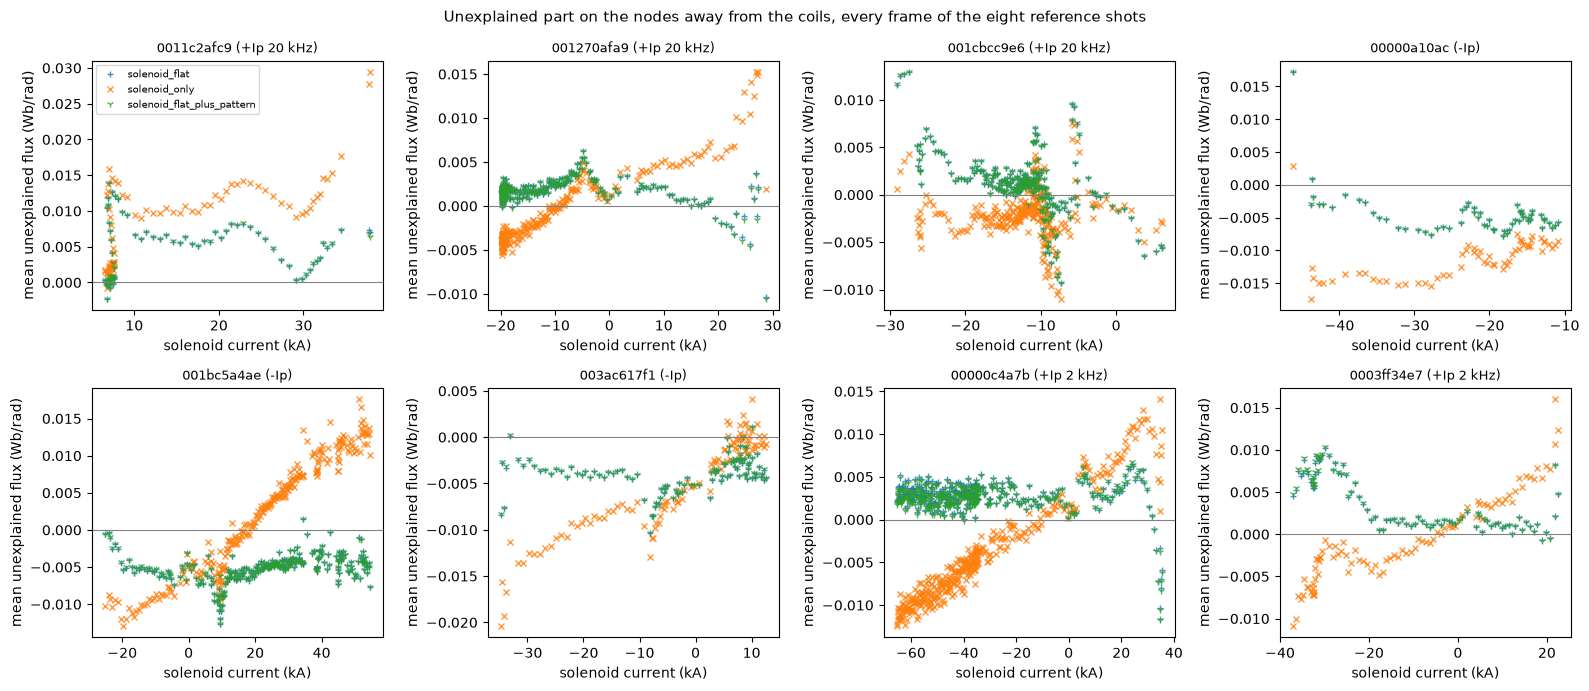

In [17]:
# The unexplained part against the solenoid current through each reference shot (D4): the mean over the fit
# nodes of (remainder minus model), per frame, from the script's mean_<variant> columns.
ref = FRAMES_FIT[FRAMES_FIT["split"] == "reference"]
markers = {HEADLINE: ".", "solenoid_only": "x", "solenoid_flat": "+", "solenoid_flat_plus_pattern": "1"}
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, shot_id in zip(axes.ravel(), SHOT_IDS):
    sub = ref[ref["shot"] == shot_id].sort_values("frame")
    for name, marker in markers.items():
        ax.plot(sub["sol_ka"], sub[f"mean_{name}"], marker, ms=5, alpha=0.8, label=name)
    ax.axhline(0.0, color="0.5", lw=0.8)
    ax.set_title(f"{shot_id} ({KIND_LABEL[KIND_OF[shot_id]]})", fontsize=9)
    ax.set_xlabel("solenoid current (kA)")
    ax.set_ylabel("mean unexplained flux (Wb/rad)")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Unexplained part on the nodes away from the coils, every frame of the eight reference shots", fontsize=11)
fig.tight_layout()
print("fit frames by phase: median of the mean unexplained flux over the flux range, and its correlation with the "
      "solenoid current, per variant (for a *_constant variant the mean residual is the frame's constant)")
fit_frames = FRAMES_FIT[FRAMES_FIT["split"] == "fit"]
summary = {}
for name in VARIANTS:
    g = fit_frames.groupby("phase", sort=False)
    summary[name] = pd.DataFrame({"median_over_range": g.apply(lambda x: (x[f"mean_{name}"] / x["flux_range"]).median(), include_groups=False),
                                  "corr_with_sol": g.apply(lambda x: x[f"mean_{name}"].corr(x["sol_ka"]), include_groups=False)}).reindex(PHASES)
display(pd.concat(summary, axis=1).T)

## 5. Mirror check and X-point counts (D9)

K8 compares the coil flux of a frame with the A and B currents swapped, flipped in Z, against the
original. The report marks it as failed at 1.8 percent of the flux range. The cells below locate
the difference: the grid, the solenoid and each A/B pair are tested one at a time, on their
geometry (position, size, skew) and on their Green's patterns. Then the frames are counted by
the position of the X-point, with the proxy of `coil_scales.xpoint_class` written by the fit
script for every frame: the boundary point with the smallest poloidal field, and "both" when
the other half of the boundary holds a comparable minimum. The scorer has no X-point finder.

In [18]:
geometry = GEOMETRY["DIII-D"]
SOL = int(TABLE.column_index([CFG.solenoid_column])[0])
print(f"K8 from the fit: {FIT['k8_mirror']:.2e} of the flux range ({'pass' if FIT['k8_mirror'] < 1e-3 else 'fail'} at 1e-3)")
print(f"grid symmetric about Z = 0: {np.allclose(TABLE.grid_z, -TABLE.grid_z[::-1])}")
rows = []
for i, j in cs.mirror_pairs(TABLE.columns, CFG):
    a, b = TABLE.columns[i], TABLE.columns[j]
    ia, ib = geometry.elements_of(a)[0], geometry.elements_of(b)[0]
    pa, pb = TABLE.patterns[i], TABLE.patterns[j]
    rows.append({"pair": a.replace("magnetics_", "") + "/" + b.replace("magnetics_", ""),
                 "R_A - R_B (mm)": 1e3 * (geometry.r[ia] - geometry.r[ib]), "Z_A + Z_B (mm)": 1e3 * (geometry.z[ia] + geometry.z[ib]),
                 "width diff (mm)": 1e3 * (geometry.width[ia] - geometry.width[ib]), "height diff (mm)": 1e3 * (geometry.height[ia] - geometry.height[ib]),
                 "angle1 sum": geometry.angle1[ia] + geometry.angle1[ib], "angle2 sum": geometry.angle2[ia] + geometry.angle2[ib],
                 "pattern flip difference / range": np.abs(pa[::-1] - pb).max() / (pa.max() - pa.min())})
sol_pattern = TABLE.patterns[SOL]
ie = geometry.elements_of(CFG.solenoid_column)[0]
rows.append({"pair": "ECOILA (itself)", "R_A - R_B (mm)": 0.0, "Z_A + Z_B (mm)": 2e3 * geometry.z[ie], "width diff (mm)": 0.0,
             "height diff (mm)": 0.0, "angle1 sum": 0.0, "angle2 sum": 0.0,
             "pattern flip difference / range": np.abs(sol_pattern[::-1] - sol_pattern).max() / (sol_pattern.max() - sol_pattern.min())})
MIRROR = pd.DataFrame(rows)
display(MIRROR)
# K8 per pair: a frame with current in one pair only.
per_pair = []
for i, j in cs.mirror_pairs(TABLE.columns, CFG):
    c = np.zeros(len(TABLE.columns)); c[i], c[j] = 100.0, -60.0
    per_pair.append({"pair": MIRROR["pair"].iloc[len(per_pair)], "k8_pair_only": cs.mirror_difference(TABLE, c, CFG)})
display(pd.DataFrame(per_pair))

K8 from the fit: 1.79e-02 of the flux range (fail at 1e-3)
grid symmetric about Z = 0: True


,pair,R_A - R_B (mm),Z_A + Z_B (mm),width diff (mm),height diff (mm),angle1 sum,angle2 sum,pattern flip difference / range
0,F1A/F1B,0.0,-5.4,0.0,0.0,0.0,0.0,1.9320e-02
1,F2A/F2B,0.7,-5.4,0.0,0.0,0.0,0.0,2.2672e-02
2,F3A/F3B,1.7,-5.2,0.0,0.0,0.0,0.0,2.0109e-02
3,F4A/F4B,-1.9,-5.8,0.0,0.0,0.0,0.0,2.4388e-02
4,F5A/F5B,1.6,0.0,0.0,0.0,0.0,0.0,7.3841e-03
5,F6A/F6B,0.0,0.0,0.0,0.0,0.0,0.0,4.9167e-16
6,F7A/F7B,-10.1,0.0,0.0,0.0,0.0,0.0,2.7765e-02
7,F8A/F8B,-0.6,-0.8,0.0,0.0,0.0,0.0,2.6638e-03
8,F9A/F9B,0.1,9.4,0.0,0.0,0.0,0.0,2.6753e-02
9,ECOILA (itself),0.0,0.0,0.0,0.0,0.0,0.0,1.2070e-15


,pair,k8_pair_only
0,F1A/F1B,3.0348e-02
1,F2A/F2B,1.6278e-02
2,F3A/F3B,1.3136e-02
3,F4A/F4B,1.5324e-02
4,F5A/F5B,4.6569e-03
5,F6A/F6B,3.6624e-16
6,F7A/F7B,1.9636e-02
7,F8A/F8B,1.6821e-03
8,F9A/F9B,1.7307e-02


In [19]:
# Frames by X-point position (proxy), reference shots (all frames) and fit frames, by phase.
xp = FRAMES_FIT.groupby(["split", "phase"], sort=False)["xpoint"].value_counts().unstack(fill_value=0)
display(xp)
print("share over all analysed frames:")
display(FRAMES_FIT["xpoint"].value_counts(normalize=True).round(3))

xpoint               upper  lower  both
split      phase                       
reference  rising      230     53     4
           flat_top    678    337     0
           late        107     29     0
fit        rising       84    141     8
           flat_top    179    507     0
           late         33     34    10
validation rising       99    152     3
           flat_top    202    449     2
           late         32     37     2

share over all analysed frames:


xpoint
lower    0.510
upper    0.482
both     0.008
Name: proportion, dtype: float64

## 6. MAST, label-free (D5)

The two reference-point ratios of `reference_ratios.parquet`, computed from inputs only on 20
DIII-D training shots and 20 MAST test shots, and coil flux maps of MAST test shots at their
flat-top frame with the field nulls marked. No MAST equilibrium label is read.

**Coil model and sign.** The fit script evaluates each machine under its adopted coil
model: DIII-D with this fit's `solenoid_flat` record (shaping coils as stored, the flat
solenoid term, so the DIII-D solenoid flux ratio uses the fitted flat term and not a scaled
rectangle), MAST with `scales/mast_default.json`, every scale 1 and no flat term, so MAST is
unaffected by the DIII-D fit. Ip enters signed, so a negative-Ip DIII-D shot gives ratios of
the same sign as a positive one; an earlier run normalized by the magnitude of Ip and showed
one DIII-D Bz ratio near +1.7 (shot `1ca444c006`, negative Ip), which was that sign flip.

machine                DIII-D     MAST
bz_ratio       count  20.0000  20.0000
               mean   -2.1319  -1.3405
               std     0.2393   0.1604
               min    -2.6679  -1.6696
               25%    -2.2100  -1.4346
               50%    -2.0961  -1.3505
               75%    -2.0269  -1.2350
               max    -1.6928  -1.0647
sol_flux_ratio count  20.0000  20.0000
               mean   -0.1398  -0.0933
               std     0.0604   0.0463
               min    -0.2391  -0.1735
               25%    -0.1801  -0.1253
               50%    -0.1365  -0.0910
               75%    -0.1220  -0.0524
               max     0.0031  -0.0050

medians: Bz ratio DIII-D -2.096, MAST -1.351; solenoid flux ratio DIII-D -0.1365 (flat term 0.00897 Wb/rad per kA), MAST -0.0910 (656 elements per element)
DIII-D shots whose Bz ratio has the other sign: none


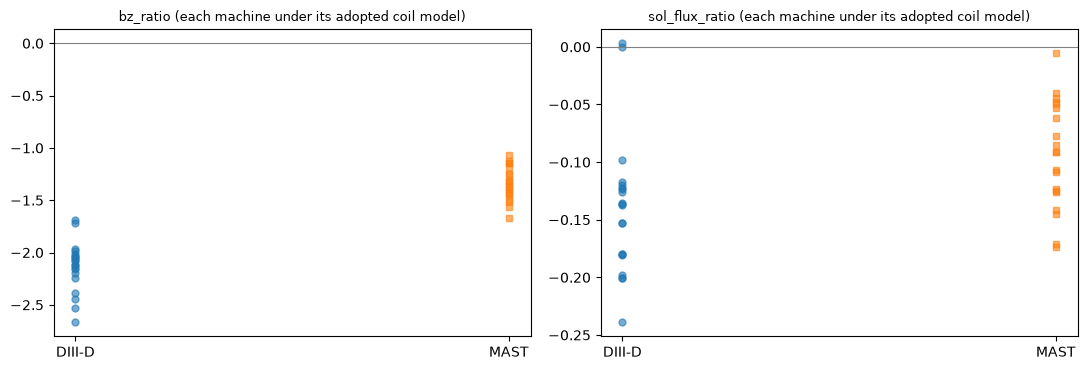

In [20]:
mast_default = CoilScales.load(REPORT_DIR / "scales" / "mast_default.json")
assert mast_default.flat_wb_per_ka == 0.0 and all(v == 1.0 for v in mast_default.scales.values())
r = RATIOS.copy()
summary = r.groupby("machine")[["bz_ratio", "sol_flux_ratio"]].describe(percentiles=[0.25, 0.5, 0.75]).T
display(summary)
print(f"medians: Bz ratio DIII-D {r.loc[r['machine'] == 'DIII-D', 'bz_ratio'].median():.3f}, MAST {r.loc[r['machine'] == 'MAST', 'bz_ratio'].median():.3f}; "
      f"solenoid flux ratio DIII-D {r.loc[r['machine'] == 'DIII-D', 'sol_flux_ratio'].median():.4f} (flat term {ADOPTED.flat_wb_per_ka:.5f} Wb/rad per kA), "
      f"MAST {r.loc[r['machine'] == 'MAST', 'sol_flux_ratio'].median():.4f} (656 elements per element)")
odd = r[(r["machine"] == "DIII-D") & (np.sign(r["bz_ratio"]) != np.sign(r.loc[r['machine'] == 'DIII-D', 'bz_ratio'].median()))]
print("DIII-D shots whose Bz ratio has the other sign:", odd[["shot", "ip_ka", "bz_ratio"]].to_dict("records") if len(odd) else "none")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, ("bz_ratio", "sol_flux_ratio")):
    for machine, marker in (("DIII-D", "o"), ("MAST", "s")):
        v = r.loc[r["machine"] == machine, col]
        ax.plot(np.full(len(v), machine), v, marker, ms=5, alpha=0.6)
    ax.set_title(col + " (each machine under its adopted coil model)", fontsize=9)
    ax.axhline(0.0, color="0.5", lw=0.8)
fig.tight_layout()

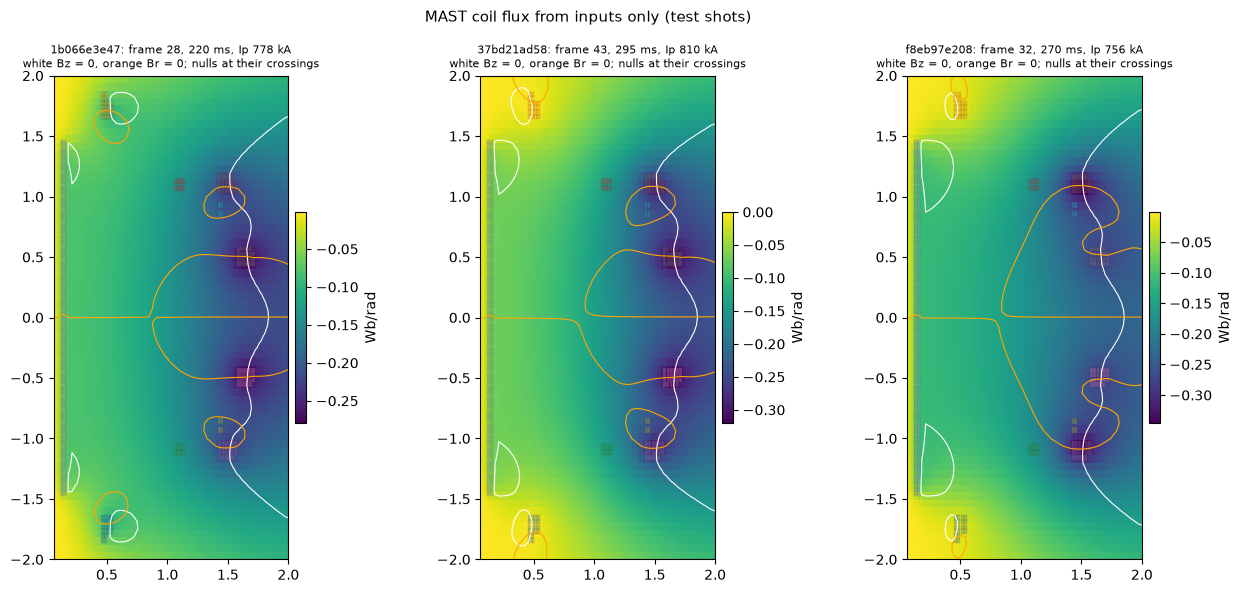

In [21]:
# MAST coil flux from inputs only, at the frame of largest |Ip| of three test shots, with the field nulls:
# the intersections of the Br = 0 and Bz = 0 contours of the coil flux (Br = -(1/R) dpsi/dZ, Bz = (1/R) dpsi/dR).
from fusion_eq.coil_flux import currents_at_frames  # noqa: E402

MCFG = machine_config("MAST")
MTABLE = TABLES["MAST"]
mast_files = dataset.select_shots(dataset.list_shots(DATA_ROOT, "mast_public_test"), 3, FIT["arguments"]["seed"] + 1)
fig, axes = plt.subplots(1, 3, figsize=(13, 6))
for ax, path in zip(axes, mast_files):
    mshot = io.load_shot(path, [*MTABLE.columns, MCFG.ip_column, "efit_times", "magnetics_time"])
    currents = currents_at_frames(mshot, MTABLE.columns, FIT["arguments"]["window_ms"])
    ip = currents_at_frames(mshot, [MCFG.ip_column], FIT["arguments"]["window_ms"])[:, 0]
    k = int(np.nanargmax(np.abs(ip)))
    flux = MTABLE.flux(currents[k], mast_default)
    gr, gz = MTABLE.grid_r, MTABLE.grid_z
    dpsi_dz, dpsi_dr = np.gradient(flux, gz, gr)
    im = ax.imshow(flux, origin="lower", extent=(gr[0], gr[-1], gz[0], gz[-1]), cmap="viridis", aspect="equal")
    ax.contour(gr, gz, dpsi_dr, levels=[0.0], colors="white", linewidths=0.8)
    ax.contour(gr, gz, dpsi_dz, levels=[0.0], colors="orange", linewidths=0.8)
    draw_coils(ax, "MAST", lw=0.3, alpha=0.3, labels=False)
    ax.set_xlim(gr[0], gr[-1]); ax.set_ylim(gz[0], gz[-1])
    ax.set_title(f"{mshot.shot_id}: frame {k}, {mshot['efit_times'][k]:.0f} ms, Ip {ip[k]:.0f} kA\n"
                 f"white Bz = 0, orange Br = 0; nulls at their crossings", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="Wb/rad")
fig.suptitle("MAST coil flux from inputs only (test shots)", fontsize=11)
fig.tight_layout()

## 7. Findings

Review conclusions of the coil-flux phase, from sections 1 to 6 and the fit of 10 October
2026 (50 fit shots, 996 frames; 8 reference shots, 1,438 frames). Findings F45 to F53 in
`docs/findings.md` carry the same numbers.

### Conventions adopted

- **Sign rule.** `psi_physical = -sign(Ip) x psi_stored`, on 8 of 8 reference shots and 24 of
  24 frames of sections 2 and 3, and on every reference frame of the fit. The scorer's
  `AXIS_SIGN` matches the orientation of positive-Ip shots only.
- **Shaping coils as stored** (kA-turn, scale 1). With a per-frame constant every per-coil
  scale lies within 0.92 to 1.10. Per-coil scales without the constant are not identifiable:
  F1A lands at 0.41 by trading against the solenoid (cosine 0.68 between the centred
  patterns) and the per-shot spread reaches an IQR of 3.4 (F3A); they are not used.
- **Solenoid as a flat term.** Its flux is flat across the grid at 0.00897 Wb/rad per kA of
  `magnetics_ECOILA`. A single scaled rectangle overstates the shape (K5 0.037 against 0.009),
  and adding the rectangle pattern to the flat term changes nothing (0.0088 against 0.0089, the
  pattern coefficient absorbed at -9.3). Adopted model: `solenoid_flat`, the package resource
  `fusion_eq/resources/coil_scales_d3d.json`, which `coil_flux` applies by default for DIII-D.
  MAST keeps the default record, every scale 1 and no flat term.

### Accuracy reached

- **Current from the map (K3).** The current density integrated inside the scorer's boundary
  matches the measured Ip: median ratio 0.997 (5th to 95th percentile 0.990 to 1.008), 0.996
  on the 2 kHz shots and 0.998 at 20 kHz. This also supports the Ip alignment of the loader.
- **Agreement outside the plasma (K5), adopted model.** Fit frames: flat-top 0.0089, late
  0.0090, rising 0.0226 of the flux range on the nodes away from the coils; 0.0096 near the
  coils. Reference frames: 0.0121, 0.0104, 0.0222. The validation table of section 4 gives the
  same quantity on shots that took no part in the fit. The ceiling with a free constant per
  frame is 0.0063 (per-coil scales) to 0.0066 (solenoid only), so the flat term reaches within
  a factor 1.4 of what any per-frame offset could give.
- **Earliest rising frames.** Frames of the rise with a solenoid current above 30 kA remain at
  5 to 7 percent (reference frames 0.051 over 44 frames, fit frames 0.074 in the 30 to 60 kA
  band) with a slope near 0.83. Candidate cause: vessel currents induced by the solenoid swing,
  which no coil pattern represents.
- **Mirror symmetry (K8).** 1.79 percent of the flux range, from the shipped geometry: the A
  and B coils of F1 to F4 are 5.4 mm off a mirror in Z, F9 by 9.4 mm, F7 differs by 10.1 mm in
  R, F6 is exact; the grid and the solenoid are symmetric. Pair by pair the effect reaches
  3.0 percent (F1). A frame mirrored in Z is therefore a valid training example only when its
  coil flux is recalculated from the swapped currents, not flipped.
- **X-point position.** On the 50 random fit shots, the proxy (the boundary point with the
  smallest poloidal field) gives lower 68.5 percent, upper 29.7 percent, both 1.8 percent;
  these are the estimate for the dataset. The reference shots (upper 70.6 percent) are not
  representative. The count is a proxy: the scorer has no X-point finder.
- **MAST, label-free (K9).** Under each machine's coil model the Bz ratio and the solenoid
  flux ratio have the same sign and order on MAST as on DIII-D (medians -1.35 against -2.09 for
  Bz; -0.091 for the MAST solenoid against the DIII-D value of the rerun). The checks rule out
  gross errors in the MAST turn conventions only. The one DIII-D Bz ratio near +1.7 of the first
  run was shot `1ca444c006`, a negative-Ip shot normalized by the magnitude of Ip; Ip now enters
  signed.

### Viability of the physics-first structure

Viable. With the shaping coils as stored and one fitted number for the solenoid, the
calculated coil flux reproduces the flux outside the plasma to about one percent of the
frame's range on flat-top and late frames, with no structure left at a shaping coil. What
remains is the plasma's own flux plus, on the earliest rising frames, a few percent that
behaves like induced vessel current.

### Decisions this phase feeds

| Decision | Outcome |
| --- | --- |
| Overall structure | Physics-first, with the solenoid as a fitted flat term |
| Sign rule | `psi_physical = -sign(Ip) x psi_stored` on DIII-D |
| Units and turns | DIII-D shaping coils in kA-turn at scale 1; solenoid column in kA with the flat term; MAST at its documented conventions, unverified beyond the label-free checks |
| Solenoid | Flat term 0.00897 Wb/rad per kA; no rectangle pattern |
| Data augmentation | Mirroring valid with recalculated coil flux |

### Carried into modelling

- DIII-D coil model: shaping coils as stored plus the flat solenoid term
  (`fusion_eq.coil_flux.coil_flux` with the adopted scales).
- Sign handling: the stored map is `-sign(Ip)` times the physical flux; inputs and targets are
  put in one frame before any model sees them.
- Up-down mirroring with recalculated coil flux, to give the model symmetric behaviour; DIII-D
  has about 1 percent double-null frames.
- Earliest rising frames: 5 to 6 percent leftover, a candidate for rate-of-change features.
- To check at the first MAST prediction: how flat MAST's calculated solenoid flux is across the
  plasma region; the stored-flux sign on MAST; a first MAST score with the coil flux alone.